# M5: дневной прогноз и WRMSSE

Прогнозируем продажи на 28 дней из одной даты для всех 30 490 пар «товар — магазин». Качество считаем на 12 уровнях иерархии M5. Основная метрика — WRMSSE: меньшее значение лучше.

**Текущий контроль:** CatBoost, 63 признака, первые 256 деревьев модели на 512. Средний WRMSSE на трёх исторических окнах — **0.65645**, локальный public WRMSSE — **0.64089**, Bias — **−4.39%**.

Public-период уже используется при разработке. Это локальная оценка по правилам M5; отправки и подтверждённого места на Kaggle пока нет.

[Первый ноутбук](01_exploration.ipynb) — недельный пилот на 100 товарах. [Второй](02_scaling.ipynb) — недельный прогноз всех товаров CA_1. Здесь меняются частота, горизонт и метрика, поэтому сравниваем дневные модели с дневными бейзлайнами.


## 0. Окружение и пути

Используем `.venv` проекта и ядро **Python (demand-planner)**. Проверяем интерпретатор и исходные CSV; public-факты дальше читаем из архива `data/raw/m5-forecasting-accuracy.zip`.

Результаты прошлых запусков сохранены в выводах и в `results/m5_wrmsse/`. Для их просмотра запускать обучение заново не нужно. Восстановление рабочего состояния после перезапуска ядра подготовим перед следующим подбором параметров.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents]
     if (path / "requirements.txt").is_file() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError("Открой ноутбук из demand-planner или notebooks.")

if Path(sys.prefix).resolve() != (PROJECT_ROOT / ".venv").resolve():
    raise RuntimeError("Выбери Python из .venv проекта.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_RAW = PROJECT_ROOT / "data" / "raw"
RESULTS = PROJECT_ROOT / "results" / "m5_wrmsse"
HORIZON = 28
RANDOM_STATE = 42

required_files = [
    "calendar.csv",
    "sales_train_validation.csv",
    "sell_prices.csv",
]
missing_files = [name for name in required_files if not (DATA_RAW / name).is_file()]

if missing_files:
    raise FileNotFoundError(f"Не найдены исходные файлы: {missing_files}")

pd.set_option("display.max_columns", 30)

print(f"Python: {sys.version.split()[0]}")
print(f"Проект: {PROJECT_ROOT}")
print(f"Горизонт: {HORIZON} дней из одной даты")


Python: 3.12.14
Проект: /Users/daniilsestov/Desktop/pet_projects/demand-planner
Горизонт: 28 дней из одной даты


## 1. Даты и правила проверки

| Период | Дни M5 | Для чего используем |
|---|---|---|
| До 24 апреля 2016 | `d_1` — `d_1913` | История для воспроизведения public-постановки |
| 25 апреля — 22 мая 2016 | `d_1914` — `d_1941` | Период public leaderboard, теперь используем для разработки |
| 23 мая — 19 июня 2016 | `d_1942` — `d_1969` | Период private leaderboard, резервируем для итоговой проверки |

Апрель–май уже смотрели во втором ноутбуке для CA_1. Независимым финальным тестом следующей версии он больше не является. До итоговой проверки выбираем варианты на нескольких исторических 28-дневных окнах. Ответы private-периода понадобятся из опубликованных организаторами данных; в исходных CSV архива истории до `d_1941` их нет.

Для каждого окна фиксируем одну дату прогноза. На следующие 28 дней используем только доступную к ней историю и заранее известные внешние признаки. Реальные продажи внутри прогнозируемых 28 дней в лаги не подставляем.


In [2]:
calendar = pd.read_csv(DATA_RAW / "calendar.csv", parse_dates=["date"])
calendar_by_day = calendar.set_index("d")

periods = pd.DataFrame([
    {"period": "История", "first_day": "d_1", "last_day": "d_1913"},
    {"period": "Public / разработка", "first_day": "d_1914", "last_day": "d_1941"},
    {"period": "Private / финальная проверка", "first_day": "d_1942", "last_day": "d_1969"},
])

periods["start"] = periods["first_day"].map(calendar_by_day["date"])
periods["end"] = periods["last_day"].map(calendar_by_day["date"])
periods["days"] = (periods["end"] - periods["start"]).dt.days + 1

assert periods.loc[periods["period"].ne("История"), "days"].eq(HORIZON).all()
display(periods.set_index("period"))


,first_day,last_day,start,end,days
period,,,,,
История,d_1,d_1913,2011-01-29,2016-04-24,1913
Public / разработка,d_1914,d_1941,2016-04-25,2016-05-22,28
Private / финальная проверка,d_1942,d_1969,2016-05-23,2016-06-19,28


## 2. Состав данных и иерархия

Используем все 3 049 товаров во всех десяти магазинах: 30 490 исходных рядов. Их прогнозы суммируются до товара, магазина, категории, штата и остальных групп. Всего получается 42 840 рядов на 12 уровнях.

Сначала загружаем идентификаторы и проверяем число групп. Затем читаем дневную историю в широкую таблицу; длинную таблицу всех наблюдений не создаём.


In [3]:
identifier_columns = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

series_metadata = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=identifier_columns,
    dtype="string",
)

assert not series_metadata.duplicated(["item_id", "store_id"]).any()
assert len(series_metadata) == 30_490
assert series_metadata["store_id"].nunique() == 10

M5_LEVELS = {
    "Total": [],
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "State / Category": ["state_id", "cat_id"],
    "State / Department": ["state_id", "dept_id"],
    "Store / Category": ["store_id", "cat_id"],
    "Store / Department": ["store_id", "dept_id"],
    "Item": ["item_id"],
    "Item / State": ["item_id", "state_id"],
    "Item / Store": ["item_id", "store_id"],
}

hierarchy = pd.DataFrame([
    {
        "level": level,
        "series": (
            series_metadata.groupby(columns, observed=True).ngroups
            if columns else 1
        ),
    }
    for level, columns in M5_LEVELS.items()
]).set_index("level")

assert int(hierarchy["series"].sum()) == 42_840
display(hierarchy)
print(f"Всего оцениваемых рядов: {hierarchy['series'].sum():,}")


,series
level,
Total,1
State,3
Store,10
Category,3
Department,7
State / Category,9
State / Department,21
Store / Category,30
Store / Department,70


Всего оцениваемых рядов: 42,840


## 3. WRMSSE

Для каждого ряда считаем RMSSE:

$$
\mathrm{RMSSE}_i =
\sqrt{\frac{\frac{1}{28}\sum_{h=1}^{28}(y_{i,T+h}-\hat y_{i,T+h})^2}
{\frac{1}{n_i-1}\sum_{t=2}^{n_i}(y_{i,t}-y_{i,t-1})^2}}.
$$

В знаменателе оставляем историю начиная с первой ненулевой продажи. Масштаб показывает обычную величину дневных изменений ряда. В числителе — средняя квадратичная ошибка прогноза на следующие 28 дней.

RMSSE взвешиваются по денежным продажам последних 28 дней доступной истории. Внутри уровня нормированные веса дают единицу, доля каждого из 12 уровней в итоговом WRMSSE равна 1/12. Целевая переменная — проданные единицы.

Ниже реализован оценщик с проверками дат, порядка рядов, цен, масштабов и весов. **Независимую сверку с эталонным расчётом организаторов ещё нужно сделать.** Для каждого исторического окна масштабы и веса рассчитываются заново по истории до даты прогноза.


### 3.1. История продаж и цены для весов

Читаем `d_1–d_1913`, выравниваем строки по идентификаторам и заменяем номера дней датами. Для денежных весов public-окна загружаем цены последних 28 дней истории.


In [4]:
M5_KEYS = ["store_id", "item_id"]
TRAIN_END_DAY = 1913

train_day_columns = [
    f"d_{day}" for day in range(1, TRAIN_END_DAY + 1)
]

series_index = pd.MultiIndex.from_frame(
    series_metadata[M5_KEYS]
)

train_daily = pd.read_csv(
    DATA_RAW / "sales_train_validation.csv",
    usecols=[*M5_KEYS, *train_day_columns],
    dtype={
        "store_id": "string",
        "item_id": "string",
        **{column: "int32" for column in train_day_columns},
    },
)

train_daily = (
    train_daily
    .set_index(M5_KEYS)
    .reindex(series_index)
    .loc[:, train_day_columns]
)

train_daily.columns = pd.DatetimeIndex(
    calendar.set_index("d").loc[train_day_columns, "date"],
    name="date",
)

weight_dates = train_daily.columns[-28:]

weight_weeks = (
    calendar.set_index("date")
    .loc[weight_dates, "wm_yr_wk"]
    .unique()
)

price_parts = []

for chunk in pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    usecols=["store_id", "item_id", "wm_yr_wk", "sell_price"],
    dtype={
        "store_id": "string",
        "item_id": "string",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
    chunksize=200_000,
):
    selected = chunk.loc[
        chunk["wm_yr_wk"].isin(weight_weeks)
    ]

    if not selected.empty:
        price_parts.append(selected.copy())

prices_for_weights = pd.concat(
    price_parts,
    ignore_index=True,
)

del price_parts

print(f"Рядов: {len(train_daily):,}")
print(f"Дней истории: {train_daily.shape[1]:,}")
print(
    "Период для весов:",
    weight_dates.min().date(),
    "—",
    weight_dates.max().date(),
)

Рядов: 30,490
Дней истории: 1,913
Период для весов: 2016-03-28 — 2016-04-24


### 3.2. Расчёт метрики

`calculate_rmsse_scale` считает масштабы без ведущих нулей. Класс `M5WRMSSE` строит агрегации и веса, а затем оценивает ошибки на каждом уровне. Положительный вес при нулевом масштабе вызывает ошибку, чтобы такая ситуация не исчезла из оценки незаметно.


In [5]:
from scipy.sparse import csr_matrix


def calculate_rmsse_scale(history_values, aggregation, block_size=128):
    n_groups = aggregation.shape[0]
    n_days = history_values.shape[1]

    first_nonzero = np.full(n_groups, n_days, dtype=np.int32)
    squared_difference_sum = np.zeros(n_groups, dtype=np.float64)
    previous = np.zeros(n_groups, dtype=np.float64)

    for start in range(0, n_days, block_size):
        stop = min(start + block_size, n_days)

        block = np.asarray(
            aggregation @ history_values[:, start:stop],
            dtype=np.float64,
        )

        positive = block > 0
        newly_active = (
            (first_nonzero == n_days)
            & positive.any(axis=1)
        )

        if newly_active.any():
            first_nonzero[newly_active] = (
                start
                + positive[newly_active].argmax(axis=1)
            )

        differences = np.empty_like(block)
        differences[:, 0] = block[:, 0] - previous
        differences[:, 1:] = np.diff(block, axis=1)

        positions = np.arange(start, stop)
        exclude = positions[None, :] <= first_nonzero[:, None]
        differences[exclude] = 0.0

        squared_difference_sum += np.einsum(
            "ij,ij->i",
            differences,
            differences,
        )

        previous = block[:, -1].copy()

    difference_count = n_days - first_nonzero - 1

    return np.divide(
        squared_difference_sum,
        difference_count,
        out=np.zeros(n_groups, dtype=np.float64),
        where=difference_count > 0,
    )


class M5WRMSSE:
    def __init__(
        self,
        history,
        metadata,
        calendar,
        prices,
        levels,
        horizon=28,
    ):
        if len(metadata) != 30_490 or len(levels) != 12:
            raise ValueError(
                "Для полного M5 нужны 30 490 рядов и 12 уровней."
            )

        self.series_index = pd.MultiIndex.from_frame(
            metadata[M5_KEYS]
        )

        if (
            self.series_index.has_duplicates
            or history.index.has_duplicates
            or len(history) != len(self.series_index)
            or not self.series_index.isin(history.index).all()
        ):
            raise ValueError("Идентификаторы истории и metadata не совпадают.")

        history = history.reindex(self.series_index)

        if history.shape[1] < 28:
            raise ValueError("Для расчёта весов нужны минимум 28 дней.")

        if not isinstance(history.columns, pd.DatetimeIndex):
            raise TypeError("Столбцы истории должны содержать даты.")

        expected_history_dates = pd.date_range(
            history.columns[0],
            periods=history.shape[1],
            freq="D",
        )

        if not history.columns.equals(expected_history_dates):
            raise ValueError("В истории есть пропуски или нарушен порядок дней.")

        history_values = history.to_numpy(copy=False)

        if (
            not np.isfinite(history_values).all()
            or (history_values < 0).any()
        ):
            raise ValueError("История должна содержать конечные неотрицательные продажи.")

        self.horizon = horizon
        self.n_levels = len(levels)
        self.forecast_dates = pd.date_range(
            history.columns[-1] + pd.Timedelta(days=1),
            periods=horizon,
            freq="D",
            name="date",
        )

        recent_dates = history.columns[-28:]

        week_codes = (
            calendar.set_index("date")
            .reindex(recent_dates)["wm_yr_wk"]
            .to_numpy()
        )

        if pd.isna(week_codes).any():
            raise ValueError("В календаре отсутствуют даты для расчёта весов.")

        known_prices = prices["sell_price"].dropna().to_numpy()

        if (
            not np.isfinite(known_prices).all()
            or (known_prices <= 0).any()
        ):
            raise ValueError("Известные цены должны быть конечными и положительными.")

        price_table = prices.pivot(
            index=M5_KEYS,
            columns="wm_yr_wk",
            values="sell_price",
        )

        daily_prices = price_table.reindex(
            index=self.series_index,
            columns=week_codes,
        ).to_numpy(dtype=np.float64)

        recent_units = history.iloc[:, -28:].to_numpy(
            dtype=np.float64
        )

        missing_price_with_sales = (
            (recent_units > 0)
            & ~np.isfinite(daily_prices)
        )

        if missing_price_with_sales.any():
            raise ValueError(
                "Есть положительные продажи без цены: веса нельзя посчитать корректно."
            )

        dollar_sales = (
            recent_units
            * np.nan_to_num(daily_prices, nan=0.0)
        ).sum(axis=1)

        total_dollar_sales = dollar_sales.sum()

        if total_dollar_sales <= 0:
            raise ValueError("Суммарные денежные продажи равны нулю.")

        metadata = metadata.reset_index(drop=True)

        self.level_specs = {}
        level_rows = []

        for level_name, columns in levels.items():
            if columns:
                group_index = pd.MultiIndex.from_frame(
                    metadata[columns]
                )
                codes, groups = pd.factorize(
                    group_index,
                    sort=True,
                )
                n_groups = len(groups)
            else:
                codes = np.zeros(len(metadata), dtype=np.int32)
                n_groups = 1

            aggregation = csr_matrix(
                (
                    np.ones(len(metadata), dtype=np.float64),
                    (codes, np.arange(len(metadata))),
                ),
                shape=(n_groups, len(metadata)),
            )

            print(f"Масштабы: {level_name} — {n_groups:,} рядов")

            scale = calculate_rmsse_scale(
                history_values,
                aggregation,
            )

            group_dollar_sales = np.asarray(
                aggregation @ dollar_sales
            ).ravel()

            weights = (
                group_dollar_sales
                / total_dollar_sales
                / self.n_levels
            )

            if ((scale <= 0) & (weights > 0)).any():
                raise ValueError(
                    f"{level_name}: есть ряд с положительным весом "
                    "и нулевым масштабом RMSSE."
                )

            self.level_specs[level_name] = {
                "aggregation": aggregation,
                "scale": scale,
                "weights": weights,
            }

            level_rows.append({
                "level": level_name,
                "series": n_groups,
                "weight_sum": weights.sum(),
            })

        self.level_info = (
            pd.DataFrame(level_rows)
            .set_index("level")
        )

        if self.level_info["series"].sum() != 42_840:
            raise ValueError("Получено неверное число рядов иерархии.")

        if not np.isclose(self.level_info["weight_sum"].sum(), 1.0):
            raise ValueError("Сумма весов WRMSSE отличается от единицы.")

    def _aligned_values(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("Передай DataFrame с идентификаторами и датами.")

        if (
            frame.index.has_duplicates
            or len(frame) != len(self.series_index)
            or not self.series_index.isin(frame.index).all()
        ):
            raise ValueError("Набор товаров и магазинов не совпадает.")

        if not frame.columns.equals(self.forecast_dates):
            raise ValueError(
                "Столбцы должны содержать следующие 28 дат "
                "в правильном порядке."
            )

        values = frame.reindex(self.series_index).to_numpy(
            dtype=np.float64
        )

        if not np.isfinite(values).all():
            raise ValueError("В фактах или прогнозах есть NaN либо бесконечность.")

        return values

    def score(self, actual, prediction):
        actual_values = self._aligned_values(actual)
        prediction_values = self._aligned_values(prediction)

        bottom_errors = prediction_values - actual_values
        rows = []

        for level_name, spec in self.level_specs.items():
            aggregated_errors = (
                spec["aggregation"] @ bottom_errors
            )

            mse = np.mean(
                np.square(aggregated_errors),
                axis=1,
            )

            rmsse = np.sqrt(
                np.divide(
                    mse,
                    spec["scale"],
                    out=np.zeros_like(mse),
                    where=spec["scale"] > 0,
                )
            )

            contribution = float(
                np.dot(spec["weights"], rmsse)
            )

            rows.append({
                "level": level_name,
                "weighted_RMSSE": contribution * self.n_levels,
                "contribution": contribution,
            })

        report = pd.DataFrame(rows).set_index("level")
        overall = float(report["contribution"].sum())

        return overall, report

### 3.3. Проверка структуры оценщика

Создаём public-оценщик. Проверяем 42 840 рядов и сумму весов, равную единице; выводим следующие 28 дат.


In [6]:
wrmsse_evaluator = M5WRMSSE(
    history=train_daily,
    metadata=series_metadata,
    calendar=calendar,
    prices=prices_for_weights,
    levels=M5_LEVELS,
    horizon=HORIZON,
)

display(
    wrmsse_evaluator.level_info.style.format({
        "series": "{:,.0f}",
        "weight_sum": "{:.6f}",
    })
)

print(
    "Всего рядов:",
    f"{wrmsse_evaluator.level_info['series'].sum():,}",
)

print(
    "Сумма весов:",
    f"{wrmsse_evaluator.level_info['weight_sum'].sum():.6f}",
)

print(
    "Даты будущего прогноза:",
    wrmsse_evaluator.forecast_dates.min().date(),
    "—",
    wrmsse_evaluator.forecast_dates.max().date(),
)

Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов


,series,weight_sum
level,,
Total,1,0.083333
State,3,0.083333
Store,10,0.083333
Category,3,0.083333
Department,7,0.083333
State / Category,9,0.083333
State / Department,21,0.083333
Store / Category,30,0.083333
Store / Department,70,0.083333


Всего рядов: 42,840
Сумма весов: 1.000000
Даты будущего прогноза: 2016-04-25 — 2016-05-22


## 4. Дневные бейзлайны

Сравниваем три прогноза из одной даты:

- повтор последней известной недели четыре раза;
- средние продажи соответствующего дня недели за последние четыре недели;
- повтор последнего известного блока из 28 дней.

Для всех методов одинаковы факты, горизонт, веса и масштабы. Сохраняем общий WRMSSE, Bias и ошибки по уровням иерархии.


### 4.1. Фактические продажи public-периода

Из `sales_train_evaluation.csv` внутри архива читаем только факты `d_1914–d_1941`. Проверяем набор пар «товар — магазин» и порядок дат. Эти значения нужны для оценки, в обучение public-модели они не попадают.


In [7]:
from zipfile import ZipFile

target_day_columns = [
    f"d_{day}"
    for day in range(
        TRAIN_END_DAY + 1,
        TRAIN_END_DAY + HORIZON + 1,
    )
]

target_dates = pd.DatetimeIndex(
    calendar.set_index("d").loc[target_day_columns, "date"],
    name="date",
)

if not target_dates.equals(wrmsse_evaluator.forecast_dates):
    raise ValueError("Даты фактов не совпадают с периодом оценщика.")

with ZipFile(DATA_RAW / "m5-forecasting-accuracy.zip") as archive:
    members = [
        name for name in archive.namelist()
        if Path(name).name == "sales_train_evaluation.csv"
    ]

    if len(members) != 1:
        raise ValueError("Не найден единственный sales_train_evaluation.csv.")

    with archive.open(members[0]) as source:
        actual_daily = pd.read_csv(
            source,
            usecols=[*M5_KEYS, *target_day_columns],
            dtype={
                "store_id": "string",
                "item_id": "string",
                **{
                    column: "int32"
                    for column in target_day_columns
                },
            },
        )

actual_daily = actual_daily.set_index(M5_KEYS)
expected_index = wrmsse_evaluator.series_index

if (
    actual_daily.index.has_duplicates
    or len(actual_daily) != len(expected_index)
    or not expected_index.isin(actual_daily.index).all()
):
    raise ValueError("Набор товаров и магазинов в фактах не совпадает.")

actual_daily = (
    actual_daily
    .reindex(expected_index)
    .loc[:, target_day_columns]
)

actual_daily.columns = target_dates

print(f"Рядов: {len(actual_daily):,}")
print(f"Дней проверки: {actual_daily.shape[1]}")
print(
    "Проверка:",
    target_dates.min().date(),
    "—",
    target_dates.max().date(),
)

Рядов: 30,490
Дней проверки: 28
Проверка: 2016-04-25 — 2016-05-22


### 4.2. Три простых прогноза

Из последних 28 дней известной истории получаем недельный повтор, повтор четырёх недель и средние по дням недели. Все 28 дней прогнозируем сразу.


In [8]:
history = train_daily.reindex(expected_index)
forecast_dates = wrmsse_evaluator.forecast_dates

if history.columns[-1] + pd.Timedelta(days=1) != forecast_dates[0]:
    raise ValueError("История и дата начала прогноза не согласованы.")

last_7 = history.iloc[:, -7:].to_numpy(dtype=np.float64)
last_28 = history.iloc[:, -28:].to_numpy(dtype=np.float64)

past_weekdays = history.columns[-28:].dayofweek.to_numpy()
future_weekdays = forecast_dates.dayofweek.to_numpy()

weekday_means = np.column_stack([
    last_28[:, past_weekdays == weekday].mean(axis=1)
    for weekday in range(7)
])

forecast_arrays = {
    "Повтор последней недели": last_7[
        :, np.arange(HORIZON) % 7
    ],
    "Среднее по дням недели за 4 недели": weekday_means[
        :, future_weekdays
    ],
    "Повтор последних 28 дней": last_28,
}

baseline_forecasts = {
    name: pd.DataFrame(
        values,
        index=expected_index,
        columns=forecast_dates,
    )
    for name, values in forecast_arrays.items()
}

print("Подготовлены прогнозы:")
for name in baseline_forecasts:
    print(f"— {name}")

Подготовлены прогнозы:
— Повтор последней недели
— Среднее по дням недели за 4 недели
— Повтор последних 28 дней


### 4.3. Сравнение и сохранение

Считаем WRMSSE и смещение суммарного прогноза. Выбираем сильнейший из трёх бейзлайнов и сохраняем таблицы в `results/m5_wrmsse/public_baselines/`.


In [9]:
import json

baseline_rows = []
baseline_level_reports = {}

actual_values = actual_daily.to_numpy(dtype=np.float64)
actual_total = actual_values.sum()

if actual_total <= 0:
    raise ValueError("Фактический объём продаж должен быть положительным.")

for name, prediction in baseline_forecasts.items():
    score, level_report = wrmsse_evaluator.score(
        actual_daily,
        prediction,
    )

    errors = (
        prediction.to_numpy(dtype=np.float64)
        - actual_values
    )

    baseline_rows.append({
        "Метод": name,
        "WRMSSE": score,
        "Bias": float(errors.sum() / actual_total),
    })

    baseline_level_reports[name] = level_report

baseline_metrics = (
    pd.DataFrame(baseline_rows)
    .set_index("Метод")
    .sort_values("WRMSSE")
)

reference_score = baseline_metrics.loc[
    "Повтор последней недели",
    "WRMSSE",
]

baseline_metrics["gain_vs_repeat_week"] = (
    1 - baseline_metrics["WRMSSE"] / reference_score
    if reference_score > 0 else np.nan
)

display(baseline_metrics.style.format({
    "WRMSSE": "{:.5f}",
    "Bias": "{:+.2%}",
    "gain_vs_repeat_week": "{:+.2%}",
}))

baseline_level_scores = pd.DataFrame({
    name: report["weighted_RMSSE"]
    for name, report in baseline_level_reports.items()
}).loc[:, baseline_metrics.index]

print("Ошибки по уровням иерархии")
display(baseline_level_scores.style.format("{:.5f}"))

best_baseline_name = baseline_metrics.index[0]
best_baseline_score = float(
    baseline_metrics.loc[best_baseline_name, "WRMSSE"]
)

baseline_dir = RESULTS / "public_baselines"
baseline_dir.mkdir(parents=True, exist_ok=True)

baseline_metrics.to_csv(baseline_dir / "metrics.csv")
baseline_level_scores.to_csv(
    baseline_dir / "metrics_by_level.csv"
)

run_summary = {
    "evaluation": "local_public_period",
    "train_end": str(history.columns[-1].date()),
    "score_start": str(forecast_dates[0].date()),
    "score_end": str(forecast_dates[-1].date()),
    "horizon": HORIZON,
    "bottom_series": len(expected_index),
    "aggregated_series": int(
        wrmsse_evaluator.level_info["series"].sum()
    ),
    "best_baseline": best_baseline_name,
    "best_WRMSSE": best_baseline_score,
}

_ = (baseline_dir / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"Лучший бейзлайн: {best_baseline_name}")
print(f"Исходный WRMSSE: {best_baseline_score:.5f}")
print(f"Результаты сохранены: {baseline_dir}")

,WRMSSE,Bias,gain_vs_repeat_week
Метод,,,
Среднее по дням недели за 4 недели,0.75242,-3.91%,+13.49%
Повтор последних 28 дней,0.83773,-3.91%,+3.68%
Повтор последней недели,0.86970,-7.36%,+0.00%


Ошибки по уровням иерархии


Метод,Среднее по дням недели за 4 недели,Повтор последних 28 дней,Повтор последней недели
level,,,
Total,0.60561,0.62889,0.75143
State,0.64686,0.68915,0.75440
Store,0.69878,0.74857,0.79930
Category,0.64273,0.65653,0.76205
Department,0.72484,0.75728,0.81709
State / Category,0.68639,0.71905,0.78298
State / Department,0.75401,0.80416,0.83044
Store / Category,0.73778,0.79383,0.83926
Store / Department,0.79911,0.87579,0.89186


Лучший бейзлайн: Среднее по дням недели за 4 недели
Исходный WRMSSE: 0.75242
Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_baselines


Лучший из трёх бейзлайнов — среднее по дням недели за четыре недели: **WRMSSE 0.75242**, Bias **−3.91%** на public. Это отправная точка дневной версии проекта.


## 5. Первый CatBoost

Начинаем с 25 признаков: идентификаторы товара и магазина, средние и разброс прошлых продаж, доля нулей, лаги, день недели, горизонт, календарь и SNAP.

Все признаки продаж используют историю до даты прогноза. Календарь целевого дня известен заранее. Реальные продажи внутри прогнозируемых 28 дней при построении признаков не используются.

Первая модель обучается с `Tweedie:variance_power=1.5`. Начальные 512 деревьев выбраны по Tweedie на внутреннем окне. Затем это число фиксируем для сравнения блоков признаков. Позже отдельно подбираем число деревьев по WRMSSE.


In [10]:
daily_categorical_features = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
]

daily_history = train_daily.reindex(
    wrmsse_evaluator.series_index
)

daily_history_dates = daily_history.columns
daily_history_values = daily_history.to_numpy(copy=False)

daily_identifiers = (
    series_metadata
    .set_index(M5_KEYS)
    .loc[wrmsse_evaluator.series_index]
    .reset_index()
    .loc[:, daily_categorical_features]
)

daily_identifiers.index = wrmsse_evaluator.series_index

for column in daily_categorical_features:
    daily_identifiers[column] = (
        daily_identifiers[column].astype("category")
    )

daily_calendar = calendar.set_index("date")


def make_daily_features(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)

    horizon = (target_date - forecast_origin).days

    if not 1 <= horizon <= HORIZON:
        raise ValueError("Горизонт должен быть от 1 до 28 дней.")

    origin_position = daily_history_dates.get_indexer(
        [forecast_origin]
    )[0]

    if origin_position < 55:
        raise ValueError(
            "Дата прогноза должна присутствовать в истории "
            "и иметь минимум 56 доступных дней."
        )

    X = daily_identifiers.copy()
    known_history = daily_history_values[
        :, :origin_position + 1
    ]

    for window in (7, 28, 56):
        X[f"mean_{window}d"] = (
            known_history[:, -window:]
            .mean(axis=1)
            .astype("float32")
        )

    recent_28 = known_history[:, -28:]

    X["std_28d"] = (
        recent_28.std(axis=1, ddof=1).astype("float32")
    )

    X["zero_share_28d"] = (
        (recent_28 == 0).mean(axis=1).astype("float32")
    )

    X["trend_7d_28d"] = (
        X["mean_7d"] - X["mean_28d"]
    ).astype("float32")

    recent_dates = daily_history_dates[
        origin_position - 27:origin_position + 1
    ]

    weekday_mask = (
        recent_dates.dayofweek == target_date.dayofweek
    )

    X["weekday_mean_4w"] = (
        recent_28[:, weekday_mask]
        .mean(axis=1)
        .astype("float32")
    )

    for lag in (28, 35, 42, 56, 364):
        source_date = target_date - pd.Timedelta(days=lag)

        if source_date > forecast_origin:
            raise ValueError("Лаг обращается к неизвестному будущему.")

        source_position = daily_history_dates.get_indexer(
            [source_date]
        )[0]

        if source_position >= 0:
            X[f"lag_{lag}d"] = daily_history_values[
                :, source_position
            ].astype("float32")
        else:
            X[f"lag_{lag}d"] = np.float32(np.nan)

    calendar_values = daily_calendar.loc[target_date]

    target_features = {
        "horizon": horizon,
        "day_of_week": target_date.dayofweek,
        "day_of_month": target_date.day,
        "month": target_date.month,
        "week_of_year": int(target_date.isocalendar().week),
        "year": target_date.year,
    }

    for name, value in target_features.items():
        X[name] = np.int16(value)

    snap_by_state = {
        state: int(calendar_values[f"snap_{state}"])
        for state in ("CA", "TX", "WI")
    }

    X["snap"] = (
        X["state_id"]
        .map(snap_by_state)
        .astype("int8")
    )

    X["has_event"] = np.int8(
        pd.notna(calendar_values["event_name_1"])
        or pd.notna(calendar_values["event_name_2"])
    )

    return X

In [11]:
example_origin = daily_history_dates[-1]
example_target = wrmsse_evaluator.forecast_dates[9]

feature_example = make_daily_features(
    forecast_origin=example_origin,
    target_date=example_target,
)

daily_feature_columns = feature_example.columns.tolist()

print("Дата прогноза:", example_origin.date())
print("Прогнозируемый день:", example_target.date())
print(f"Строк: {len(feature_example):,}")
print(f"Признаков: {len(daily_feature_columns)}")

display(feature_example.head())

Дата прогноза: 2016-04-24
Прогнозируемый день: 2016-05-04
Строк: 30,490
Признаков: 25


item_id    dept_id   cat_id store_id state_id  \
store_id item_id                                                              
CA_1     HOBBIES_1_001  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1       CA   
         HOBBIES_1_002  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1       CA   
         HOBBIES_1_003  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1       CA   
         HOBBIES_1_004  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1       CA   
         HOBBIES_1_005  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1       CA   

                         mean_7d  mean_28d  mean_56d   std_28d  \
store_id item_id                                                 
CA_1     HOBBIES_1_001  1.142857  0.964286  0.982143  1.137969   
         HOBBIES_1_002  0.142857  0.071429  0.196429  0.262265   
         HOBBIES_1_003  0.857143  0.571429  0.553571  0.690066   
         HOBBIES_1_004  2.571429  1.821429  1.857143  1.886670   
         HOBBIES_1_005  1.714286  1.357143  1.232143  1.282771   

                        zero_share_28d  trend_7d_28d  weekday_mean_4w  \
store_id item_id                                                        
CA_1     HOBBIES_1_001        0.428571      0.178571             0.75   
         HOBBIES_1_002        0.928571      0.071429             0.25   
         HOBBIES_1_003        0.535714      0.285714             0.50   
         HOBBIES_1_004        0.321429      0.750000             1.00   
         HOBBIES_1_005        0.250000      0.357143             1.50   

                        lag_28d  lag_35d  lag_42d  lag_56d  lag_364d  horizon  \
store_id item_id                                                                
CA_1     HOBBIES_1_001      2.0      0.0      2.0      1.0       0.0       10   
         HOBBIES_1_002      0.0      0.0      0.0      0.0       0.0       10   
         HOBBIES_1_003      0.0      0.0      0.0      0.0       0.0       10   
         HOBBIES_1_004      1.0      0.0      3.0      0.0       1.0       10   
         HOBBIES_1_005      0.0      4.0      1.0      1.0       0.0       10   

                        day_of_week  day_of_month  month  week_of_year  year  \
store_id item_id                                                               
CA_1     HOBBIES_1_001            2             4      5            18  2016   
         HOBBIES_1_002            2             4      5            18  2016   
         HOBBIES_1_003            2             4      5            18  2016   
         HOBBIES_1_004            2             4      5            18  2016   
         HOBBIES_1_005            2             4      5            18  2016   

                        snap  has_event  
store_id item_id                         
CA_1     HOBBIES_1_001     1          0  
         HOBBIES_1_002     1          0  
         HOBBIES_1_003     1          0  
         HOBBIES_1_004     1          0  
         HOBBIES_1_005     1          0

### 5.1. Обучающая выборка

Берём 52 еженедельные даты прогноза. Для каждой выбираем два горизонта из диапазона 1–28 и все 30 490 рядов: получается 3 170 960 обучающих строк.

Обучение использует выбранные даты целевой переменной, а не все дневные строки подряд. При этом признаки могут обращаться ко всей доступной прошлой истории. Все обучающие целевые даты находятся до начала соответствующего проверочного окна.


In [12]:
import gc
import json
from time import perf_counter

from catboost import CatBoostRegressor


CB_N_ORIGINS = 52
CB_MAX_ITERATIONS = 5000
CB_LOSS = "Tweedie:variance_power=1.5"

cb_public_origin = daily_history_dates[-1]
cb_validation_origin = (
    cb_public_origin - pd.Timedelta(days=HORIZON)
)


def make_cb_training_plan(label_cutoff):
    label_cutoff = pd.Timestamp(label_cutoff)

    origins = pd.date_range(
        end=label_cutoff - pd.Timedelta(days=HORIZON),
        periods=CB_N_ORIGINS,
        freq="7D",
    )

    plan = []

    for i, origin in enumerate(origins):
        horizons = [
            (5 * i) % HORIZON + 1,
            (5 * i + HORIZON // 2) % HORIZON + 1,
        ]
        plan.append((origin, horizons))

    plan[-1] = (origins[-1], [1, HORIZON])

    return plan


def build_cb_dataset(plan, label_cutoff):
    label_cutoff = pd.Timestamp(label_cutoff)

    feature_parts = []
    target_parts = []

    for number, (origin, horizons) in enumerate(plan, start=1):
        for horizon in horizons:
            target_date = origin + pd.Timedelta(
                days=int(horizon)
            )

            target_position = daily_history_dates.get_indexer(
                [target_date]
            )[0]

            if target_position < 0 or target_date > label_cutoff:
                raise ValueError(
                    f"Недоступная дата целевой переменной: {target_date}"
                )

            features = make_daily_features(
                forecast_origin=origin,
                target_date=target_date,
            )

            feature_parts.append(
                features.loc[:, daily_feature_columns]
                .reset_index(drop=True)
            )

            target_parts.append(
                daily_history_values[:, target_position]
                .astype("float32")
            )

        if number % 13 == 0 or number == len(plan):
            print(f"Подготовлено дат: {number}/{len(plan)}")

    X = pd.concat(feature_parts, ignore_index=True)
    y = np.concatenate(target_parts)

    return X, y


print(
    "Внутренняя проверка:",
    (cb_validation_origin + pd.Timedelta(days=1)).date(),
    "—",
    cb_public_origin.date(),
)

print("\nПодготовка обучения")

cb_X_train, cb_y_train = build_cb_dataset(
    plan=make_cb_training_plan(cb_validation_origin),
    label_cutoff=cb_validation_origin,
)

print("\nПодготовка внутренней проверки")

cb_X_valid, cb_y_valid = build_cb_dataset(
    plan=[
        (
            cb_validation_origin,
            list(range(1, HORIZON + 1)),
        )
    ],
    label_cutoff=cb_public_origin,
)

print(f"\nОбучающих строк: {len(cb_X_train):,}")
print(f"Проверочных строк: {len(cb_X_valid):,}")
print(f"Признаков: {cb_X_train.shape[1]}")

Внутренняя проверка: 2016-03-28 — 2016-04-24

Подготовка обучения
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52

Подготовка внутренней проверки
Подготовлено дат: 1/1

Обучающих строк: 3,170,960
Проверочных строк: 853,720
Признаков: 25


### 5.2. Обучение первой модели

Первый fit выбирает число деревьев на окне 28 марта — 24 апреля 2016 года по Tweedie с ранней остановкой. Второй fit обучает модель с выбранными 512 деревьями на истории до public-периода. Масштабирование цели и обратное преобразование сохраняем явно.


In [13]:
cb_target_scale = max(
    1.0,
    float(cb_y_train.max()) / 1000.0,
)

cb_params = {
    "loss_function": CB_LOSS,
    "eval_metric": CB_LOSS,
    "iterations": CB_MAX_ITERATIONS,
    "learning_rate": 0.05,
    "depth": 6,
    "l2_leaf_reg": 5.0,
    "random_seed": RANDOM_STATE,
    "thread_count": 4,
    "allow_writing_files": False,
    "verbose": 200,
}

print(
    f"Обучение 1/2: выбираем число деревьев. "
    f"Лимит: {CB_MAX_ITERATIONS}."
)

cb_tuner = CatBoostRegressor(**cb_params)

cb_started = perf_counter()

cb_tuner.fit(
    cb_X_train,
    cb_y_train / cb_target_scale,
    cat_features=daily_categorical_features,
    eval_set=(
        cb_X_valid,
        cb_y_valid / cb_target_scale,
    ),
    early_stopping_rounds=100,
    use_best_model=True,
)

cb_tuning_seconds = perf_counter() - cb_started
cb_best_trees = int(cb_tuner.tree_count_)

print(f"\nВыбрано деревьев: {cb_best_trees}")
print(f"Время первого обучения: {cb_tuning_seconds / 60:.1f} мин")

del cb_X_train, cb_y_train, cb_X_valid, cb_y_valid
gc.collect()

print("\nПодготовка данных для второго обучения")

cb_X_final, cb_y_final = build_cb_dataset(
    plan=make_cb_training_plan(cb_public_origin),
    label_cutoff=cb_public_origin,
)

cb_final_params = {
    **cb_params,
    "iterations": cb_best_trees,
}

cb_model = CatBoostRegressor(**cb_final_params)

print(
    f"\nОбучение 2/2: прогноз из {cb_public_origin.date()}, "
    f"{cb_best_trees} деревьев."
)

cb_started = perf_counter()

cb_model.fit(
    cb_X_final,
    cb_y_final / cb_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

cb_final_seconds = perf_counter() - cb_started

print(f"\nВремя второго обучения: {cb_final_seconds / 60:.1f} мин")

del cb_X_final, cb_y_final
gc.collect()

Обучение 1/2: выбираем число деревьев. Лимит: 5000.
0:	learn: 4.4861621	test: 4.7091634	best: 4.7091634 (0)	total: 833ms	remaining: 1h 9m 24s
200:	learn: 3.6217318	test: 3.8718774	best: 3.8718450 (198)	total: 2m	remaining: 48m 6s
400:	learn: 3.6029105	test: 3.8703786	best: 3.8703423 (399)	total: 4m 5s	remaining: 46m 55s
600:	learn: 3.5906920	test: 3.8705381	best: 3.8700909 (511)	total: 6m 11s	remaining: 45m 15s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 3.870090917
bestIteration = 511

Shrink model to first 512 iterations.

Выбрано деревьев: 512
Время первого обучения: 6.4 мин

Подготовка данных для второго обучения
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52

Обучение 2/2: прогноз из 2016-04-24, 512 деревьев.
0:	learn: 4.5336532	total: 1.09s	remaining: 9m 16s
200:	learn: 3.6582679	total: 1m 59s	remaining: 3m 4s
400:	learn: 3.6363339	total: 3m 52s	remaining: 1m 4s
511:	learn: 3.6291013	total: 4m 56s	remaining: 

0

### 5.3. Прогноз и первый результат

Получаем ожидаемые продажи через `prediction_type="Exponent"` и возвращаем исходный масштаб. Сравниваем CatBoost с дневными бейзлайнами, сохраняем прогноз, настройки и модель.


In [14]:
cb_prediction_values = np.empty(
    (len(wrmsse_evaluator.series_index), HORIZON),
    dtype=np.float64,
)

for column_number, target_date in enumerate(
    wrmsse_evaluator.forecast_dates
):
    features = make_daily_features(
        forecast_origin=cb_public_origin,
        target_date=target_date,
    ).loc[:, daily_feature_columns]

    prediction = cb_model.predict(
        features,
        prediction_type="Exponent",
        thread_count=4,
    )

    cb_prediction_values[:, column_number] = (
        prediction * cb_target_scale
    )

    if (column_number + 1) % 7 == 0:
        print(f"Готов прогноз на {column_number + 1}/{HORIZON} дней")

if not np.isfinite(cb_prediction_values).all():
    raise ValueError("В прогнозе появились бесконечные значения или NaN.")

cb_prediction = pd.DataFrame(
    cb_prediction_values,
    index=wrmsse_evaluator.series_index,
    columns=wrmsse_evaluator.forecast_dates,
)

cb_score, cb_level_report = wrmsse_evaluator.score(
    actual_daily,
    cb_prediction,
)

cb_actual_values = (
    actual_daily
    .reindex(cb_prediction.index)
    .loc[:, cb_prediction.columns]
    .to_numpy(dtype=np.float64)
)

cb_bias = (
    cb_prediction_values.sum() / cb_actual_values.sum() - 1
)

cb_name = "CatBoost — Tweedie"

cb_comparison = baseline_metrics[["WRMSSE", "Bias"]].copy()
cb_comparison.loc[cb_name] = [cb_score, cb_bias]

cb_reference_score = float(baseline_metrics["WRMSSE"].min())

cb_comparison["gain_vs_best_baseline"] = (
    1 - cb_comparison["WRMSSE"] / cb_reference_score
)

cb_comparison = cb_comparison.sort_values("WRMSSE")

display(cb_comparison.style.format({
    "WRMSSE": "{:.5f}",
    "Bias": "{:+.2%}",
    "gain_vs_best_baseline": "{:+.2%}",
}))

cb_level_comparison = baseline_level_scores[
    [best_baseline_name]
].join(
    cb_level_report["weighted_RMSSE"].rename(cb_name)
)

print("Качество по уровням иерархии")
display(cb_level_comparison.style.format("{:.5f}"))

cb_gain = 1 - cb_score / cb_reference_score

print(f"WRMSSE CatBoost: {cb_score:.5f}")
print(f"WRMSSE лучшего baseline: {cb_reference_score:.5f}")
print(f"Снижение WRMSSE: {cb_gain:+.2%}")
print(f"Bias: {cb_bias:+.2%}")
print(f"Деревьев: {cb_best_trees}")

cb_result_dir = RESULTS / "public_catboost_v1"
cb_result_dir.mkdir(parents=True, exist_ok=True)

cb_comparison.to_csv(cb_result_dir / "metrics.csv")
cb_level_comparison.to_csv(
    cb_result_dir / "metrics_by_level.csv"
)
cb_prediction.to_csv(
    cb_result_dir / "predictions.csv.gz",
    compression="gzip",
)

cb_run_config = {
    "params": cb_final_params,
    "target_scale": cb_target_scale,
    "prediction_type": "Exponent",
    "features": daily_feature_columns,
    "categorical_features": daily_categorical_features,
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "validation_origin": str(cb_validation_origin.date()),
    "forecast_origin": str(cb_public_origin.date()),
    "WRMSSE": float(cb_score),
    "Bias": float(cb_bias),
    "gain_vs_best_baseline": float(cb_gain),
    "tuning_seconds": cb_tuning_seconds,
    "final_fit_seconds": cb_final_seconds,
}

_ = (cb_result_dir / "config.json").write_text(
    json.dumps(cb_run_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

cb_model_dir = PROJECT_ROOT / "models"
cb_model_dir.mkdir(parents=True, exist_ok=True)

cb_model.save_model(
    str(cb_model_dir / "03_daily_catboost_v1.cbm")
)

print(f"\nРезультаты сохранены: {cb_result_dir}")

Готов прогноз на 7/28 дней
Готов прогноз на 14/28 дней
Готов прогноз на 21/28 дней
Готов прогноз на 28/28 дней


,WRMSSE,Bias,gain_vs_best_baseline
Метод,,,
CatBoost — Tweedie,0.71965,-6.74%,+4.36%
Среднее по дням недели за 4 недели,0.75242,-3.91%,+0.00%
Повтор последних 28 дней,0.83773,-3.91%,-11.34%
Повтор последней недели,0.86970,-7.36%,-15.59%


Качество по уровням иерархии


,Среднее по дням недели за 4 недели,CatBoost — Tweedie
level,,
Total,0.60561,0.60687
State,0.64686,0.61926
Store,0.69878,0.68382
Category,0.64273,0.62135
Department,0.72484,0.68306
State / Category,0.68639,0.65567
State / Department,0.75401,0.70744
Store / Category,0.73778,0.71492
Store / Department,0.79911,0.76733


WRMSSE CatBoost: 0.71965
WRMSSE лучшего baseline: 0.75242
Снижение WRMSSE: +4.36%
Bias: -6.74%
Деревьев: 512

Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_catboost_v1


## 6. История цены

Добавляем девять признаков: последнюю известную цену, изменения за одну и четыре недели, отклонения от средних и максимума, разброс и долю недель с записью о цене. Получается 34 признака.

Используем неделю даты прогноза и более ранние недели. Будущие цены не подставляем; отсутствие записи о цене не трактуем как доказательство отсутствия товара на складе.


In [15]:
import gc
import json
from functools import lru_cache

from catboost import CatBoostRegressor


if "cb_tuner" not in globals() or "cb_model" not in globals():
    raise RuntimeError(
        "Нужны модели из предыдущего блока в текущем ядре."
    )

price_base_columns = list(daily_feature_columns)
price_tree_count = int(cb_tuner.tree_count_)
price_target_scale = float(cb_target_scale)

if int(cb_model.tree_count_) != price_tree_count:
    raise ValueError("У исходных моделей различается число деревьев.")

price_data = pd.read_csv(
    DATA_RAW / "sell_prices.csv",
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float64",
    },
)

price_week_starts = (
    calendar.groupby("wm_yr_wk")["date"]
    .min()
    .sort_values()
)

price_week_order = price_week_starts.loc[
    price_week_starts <= cb_public_origin
].index

price_data = price_data.loc[
    price_data["wm_yr_wk"].isin(price_week_order)
].copy()

price_week_table = (
    price_data.pivot(
        index=M5_KEYS,
        columns="wm_yr_wk",
        values="sell_price",
    )
    .reindex(
        index=wrmsse_evaluator.series_index,
        columns=price_week_order,
    )
    .astype("float32")
)

price_last_known_table = price_week_table.ffill(axis=1)


@lru_cache(maxsize=64)
def price_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)

    week = int(
        daily_calendar.loc[forecast_origin, "wm_yr_wk"]
    )
    position = price_week_table.columns.get_loc(week)

    if position < 12:
        raise ValueError("Для признаков цены нужны 13 недель истории.")

    recent_4 = price_week_table.iloc[
        :, position - 3:position + 1
    ]
    recent_13 = price_week_table.iloc[
        :, position - 12:position + 1
    ]

    current = price_last_known_table.iloc[:, position]
    previous_1 = price_last_known_table.iloc[:, position - 1]
    previous_4 = price_last_known_table.iloc[:, position - 4]

    mean_4 = recent_4.mean(axis=1)
    mean_13 = recent_13.mean(axis=1)

    return pd.DataFrame({
        "price_last_known": current,
        "price_observed_this_week": (
            price_week_table.iloc[:, position].notna()
        ),
        "price_change_1w": current / previous_1 - 1,
        "price_change_4w": current / previous_4 - 1,
        "price_vs_mean_4w": current / mean_4 - 1,
        "price_vs_mean_13w": current / mean_13 - 1,
        "price_vs_max_13w": (
            current / recent_13.max(axis=1) - 1
        ),
        "price_relative_std_13w": (
            recent_13.std(axis=1, ddof=0) / mean_13
        ),
        "price_observed_share_13w": (
            recent_13.notna().mean(axis=1)
        ),
    }).astype("float32")


def make_daily_features_with_price(forecast_origin, target_date):
    forecast_origin = pd.Timestamp(forecast_origin)

    base = make_daily_features(
        forecast_origin=forecast_origin,
        target_date=target_date,
    )

    return base.join(
        price_features_at_origin(forecast_origin),
        validate="one_to_one",
    )


price_feature_columns = make_daily_features_with_price(
    cb_public_origin,
    cb_public_origin + pd.Timedelta(days=1),
).columns.tolist()

print(f"Признаков без цены: {len(price_base_columns)}")
print(f"Признаков с ценой: {len(price_feature_columns)}")
print(f"Деревьев в эксперименте: {price_tree_count}")

display(
    price_features_at_origin(cb_public_origin).head()
)

Признаков без цены: 25
Признаков с ценой: 34
Деревьев в эксперименте: 512


price_last_known  price_observed_this_week  \
store_id item_id                                                     
CA_1     HOBBIES_1_001              8.38                       1.0   
         HOBBIES_1_002              3.97                       1.0   
         HOBBIES_1_003              2.97                       1.0   
         HOBBIES_1_004              4.64                       1.0   
         HOBBIES_1_005              2.88                       1.0   

                        price_change_1w  price_change_4w  price_vs_mean_4w  \
store_id item_id                                                             
CA_1     HOBBIES_1_001              0.0         0.014528          0.003593   
         HOBBIES_1_002              0.0         0.000000          0.000000   
         HOBBIES_1_003              0.0         0.000000          0.000000   
         HOBBIES_1_004              0.0         0.000000          0.000000   
         HOBBIES_1_005              0.0         0.000000          0.000000   

                        price_vs_mean_13w  price_vs_max_13w  \
store_id item_id                                              
CA_1     HOBBIES_1_001       1.113796e-02               0.0   
         HOBBIES_1_002      -5.960464e-08               0.0   
         HOBBIES_1_003       0.000000e+00               0.0   
         HOBBIES_1_004       0.000000e+00               0.0   
         HOBBIES_1_005      -1.788139e-07               0.0   

                        price_relative_std_13w  price_observed_share_13w  
store_id item_id                                                          
CA_1     HOBBIES_1_001                  0.0061                       1.0  
         HOBBIES_1_002                  0.0000                       1.0  
         HOBBIES_1_003                  0.0000                       1.0  
         HOBBIES_1_004                  0.0000                       1.0  
         HOBBIES_1_005                  0.0000                       1.0

### 6.1. Историческое окно и общие функции оценки

Для окна 28 марта — 24 апреля заново рассчитываем WRMSSE по истории до 27 марта. Здесь же определяем `price_predict` и `price_evaluate`: эти функции используются и в следующих экспериментах.


In [16]:
price_inner_origin = pd.Timestamp(cb_validation_origin)

price_inner_history = daily_history.loc[
    :, :price_inner_origin
]

price_weight_weeks = daily_calendar.loc[
    price_inner_history.columns[-28:],
    "wm_yr_wk",
].unique()

price_inner_evaluator = M5WRMSSE(
    history=price_inner_history,
    metadata=series_metadata,
    calendar=calendar,
    prices=price_data.loc[
        price_data["wm_yr_wk"].isin(price_weight_weeks)
    ],
    levels=M5_LEVELS,
    horizon=HORIZON,
)

price_inner_actual = daily_history.loc[
    :, price_inner_evaluator.forecast_dates
]


def price_predict(model, origin, dates, feature_function, columns):
    values = np.empty(
        (len(wrmsse_evaluator.series_index), len(dates)),
        dtype=np.float64,
    )

    for number, target_date in enumerate(dates):
        X = feature_function(origin, target_date).loc[:, columns]

        values[:, number] = (
            model.predict(
                X,
                prediction_type="Exponent",
                thread_count=4,
            )
            * price_target_scale
        )

    if not np.isfinite(values).all():
        raise ValueError("Прогноз содержит NaN или бесконечность.")

    return pd.DataFrame(
        values,
        index=wrmsse_evaluator.series_index,
        columns=dates,
    )


def price_evaluate(evaluator, actual, prediction):
    score, report = evaluator.score(actual, prediction)

    actual_total = actual.reindex(
        index=prediction.index,
        columns=prediction.columns,
    ).to_numpy(dtype=np.float64).sum()

    metrics = {
        "WRMSSE": float(score),
        "Bias": float(
            prediction.to_numpy().sum() / actual_total - 1
        ),
    }

    return metrics, report


price_recent_28 = price_inner_history.iloc[:, -28:]

price_weekday_means = np.column_stack([
    price_recent_28.loc[
        :, price_recent_28.columns.dayofweek == weekday
    ].mean(axis=1).to_numpy()
    for weekday in range(7)
])

price_inner_baseline = pd.DataFrame(
    price_weekday_means[
        :, price_inner_evaluator.forecast_dates.dayofweek
    ],
    index=price_inner_evaluator.series_index,
    columns=price_inner_evaluator.forecast_dates,
)

price_inner_control = price_predict(
    model=cb_tuner,
    origin=price_inner_origin,
    dates=price_inner_evaluator.forecast_dates,
    feature_function=make_daily_features,
    columns=price_base_columns,
)

price_validation_rows = {}
price_validation_levels = {}

for name, prediction in {
    "Среднее по дням недели": price_inner_baseline,
    "CatBoost — без цены": price_inner_control,
}.items():
    metrics, report = price_evaluate(
        price_inner_evaluator,
        price_inner_actual,
        prediction,
    )
    price_validation_rows[name] = metrics
    price_validation_levels[name] = report

print("Историческое окно:", price_inner_evaluator.forecast_dates[0].date(),
      "—", price_inner_evaluator.forecast_dates[-1].date())

display(
    pd.DataFrame.from_dict(
        price_validation_rows,
        orient="index",
    ).style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
    })
)

Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов
Историческое окно: 2016-03-28 — 2016-04-24


,WRMSSE,Bias
Среднее по дням недели,0.65465,-0.64%
CatBoost — без цены,0.57422,-1.16%


### 6.2. Цена: историческая проверка

Собираем обучающие строки с ценовыми признаками и обучаем модель на тех же 512 деревьях. Сравниваем её с моделью без цены на одинаковых фактах.


In [17]:
def build_price_dataset(label_cutoff):
    label_cutoff = pd.Timestamp(label_cutoff)
    plan = make_cb_training_plan(label_cutoff)

    feature_parts = []
    target_parts = []

    for number, (origin, horizons) in enumerate(plan, start=1):
        for horizon in horizons:
            target_date = origin + pd.Timedelta(
                days=int(horizon)
            )

            position = daily_history_dates.get_indexer(
                [target_date]
            )[0]

            if position < 0 or target_date > label_cutoff:
                raise ValueError(
                    f"Недоступная целевая дата: {target_date}"
                )

            X = make_daily_features_with_price(
                origin,
                target_date,
            )

            feature_parts.append(
                X.loc[:, price_feature_columns]
                .reset_index(drop=True)
            )

            target_parts.append(
                daily_history_values[:, position]
                .astype("float32")
            )

        if number % 13 == 0 or number == len(plan):
            print(f"Подготовлено дат: {number}/{len(plan)}")

    return (
        pd.concat(feature_parts, ignore_index=True),
        np.concatenate(target_parts),
    )


price_params = {
    **cb_params,
    "iterations": price_tree_count,
    "verbose": 200,
}

print("Обучение 1/2: модель с ценой для исторического окна.")

price_X, price_y = build_price_dataset(price_inner_origin)

cb_price_valid_model = CatBoostRegressor(**price_params)

cb_price_valid_model.fit(
    price_X,
    price_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del price_X, price_y
gc.collect()

price_inner_prediction = price_predict(
    model=cb_price_valid_model,
    origin=price_inner_origin,
    dates=price_inner_evaluator.forecast_dates,
    feature_function=make_daily_features_with_price,
    columns=price_feature_columns,
)

price_metrics, price_report = price_evaluate(
    price_inner_evaluator,
    price_inner_actual,
    price_inner_prediction,
)

price_validation_rows["CatBoost — с ценой"] = price_metrics
price_validation_levels["CatBoost — с ценой"] = price_report

price_validation_comparison = pd.DataFrame.from_dict(
    price_validation_rows,
    orient="index",
)

price_validation_comparison["gain_vs_control"] = (
    1
    - price_validation_comparison["WRMSSE"]
    / price_validation_rows["CatBoost — без цены"]["WRMSSE"]
)

print("Сравнение на историческом окне")

display(
    price_validation_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_control": "{:+.2%}",
    })
)

Обучение 1/2: модель с ценой для исторического окна.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.4972360	total: 774ms	remaining: 6m 35s
200:	learn: 3.6219381	total: 1m 57s	remaining: 3m 2s
400:	learn: 3.6031504	total: 3m 54s	remaining: 1m 5s
511:	learn: 3.5966464	total: 5m 2s	remaining: 0us
Сравнение на историческом окне


,WRMSSE,Bias,gain_vs_control
Среднее по дням недели,0.65465,-0.64%,-14.01%
CatBoost — без цены,0.57422,-1.16%,+0.00%
CatBoost — с ценой,0.58047,-1.64%,-1.09%


### 6.3. Цена: public-период

Повторяем обучение по истории до 24 апреля. Сохраняем метрики, прогноз и настройки версии `public_catboost_price_v2`.


In [18]:
print("Обучение 2/2: модель с ценой для public-периода.")

price_X, price_y = build_price_dataset(cb_public_origin)

cb_price_model = CatBoostRegressor(**price_params)

cb_price_model.fit(
    price_X,
    price_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del price_X, price_y
gc.collect()

price_public_prediction = price_predict(
    model=cb_price_model,
    origin=cb_public_origin,
    dates=wrmsse_evaluator.forecast_dates,
    feature_function=make_daily_features_with_price,
    columns=price_feature_columns,
)

price_public_metrics, price_public_report = price_evaluate(
    wrmsse_evaluator,
    actual_daily,
    price_public_prediction,
)

price_control_metrics, price_control_report = price_evaluate(
    wrmsse_evaluator,
    actual_daily,
    cb_prediction,
)

price_public_comparison = baseline_metrics[
    ["WRMSSE", "Bias"]
].copy()

price_public_comparison.loc["CatBoost — без цены"] = [
    price_control_metrics["WRMSSE"],
    price_control_metrics["Bias"],
]

price_public_comparison.loc["CatBoost — с ценой"] = [
    price_public_metrics["WRMSSE"],
    price_public_metrics["Bias"],
]

price_public_comparison["gain_vs_control"] = (
    1
    - price_public_comparison["WRMSSE"]
    / price_control_metrics["WRMSSE"]
)

price_public_comparison = price_public_comparison.sort_values(
    "WRMSSE"
)

print("Сравнение на public-периоде")

display(
    price_public_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_control": "{:+.2%}",
    })
)

price_public_levels = pd.DataFrame({
    "Сезонный baseline": (
        baseline_level_reports[best_baseline_name]["weighted_RMSSE"]
    ),
    "CatBoost — без цены": (
        price_control_report["weighted_RMSSE"]
    ),
    "CatBoost — с ценой": (
        price_public_report["weighted_RMSSE"]
    ),
})

print("Качество по уровням иерархии")
display(price_public_levels.style.format("{:.5f}"))

price_experiment_dir = RESULTS / "public_catboost_price_v2"
price_experiment_dir.mkdir(parents=True, exist_ok=True)

price_validation_comparison.to_csv(
    price_experiment_dir / "historical_metrics.csv"
)
price_public_comparison.to_csv(
    price_experiment_dir / "public_metrics.csv"
)
price_public_levels.to_csv(
    price_experiment_dir / "public_metrics_by_level.csv"
)
price_public_prediction.to_csv(
    price_experiment_dir / "predictions.csv.gz",
    compression="gzip",
)

price_config = {
    "params": price_params,
    "target_scale": price_target_scale,
    "prediction_type": "Exponent",
    "features": price_feature_columns,
    "categorical_features": daily_categorical_features,
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "historical_origin": str(price_inner_origin.date()),
    "public_origin": str(cb_public_origin.date()),
    "price_policy": "origin_week_and_past_weeks_only",
    "historical_metrics": price_validation_rows,
    "public_metrics": price_public_metrics,
}

_ = (price_experiment_dir / "config.json").write_text(
    json.dumps(price_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

price_model_dir = PROJECT_ROOT / "models"
price_model_dir.mkdir(parents=True, exist_ok=True)

cb_price_model.save_model(
    str(price_model_dir / "03_daily_catboost_price_v2.cbm")
)

print(f"Результаты сохранены: {price_experiment_dir}")

Обучение 2/2: модель с ценой для public-периода.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.5335854	total: 791ms	remaining: 6m 44s
200:	learn: 3.6563359	total: 2m	remaining: 3m 6s
400:	learn: 3.6376641	total: 4m	remaining: 1m 6s
511:	learn: 3.6301061	total: 5m 5s	remaining: 0us
Сравнение на public-периоде


,WRMSSE,Bias,gain_vs_control
Метод,,,
CatBoost — с ценой,0.69174,-5.97%,+3.88%
CatBoost — без цены,0.71965,-6.74%,+0.00%
Среднее по дням недели за 4 недели,0.75242,-3.91%,-4.55%
Повтор последних 28 дней,0.83773,-3.91%,-16.41%
Повтор последней недели,0.86970,-7.36%,-20.85%


Качество по уровням иерархии


,Сезонный baseline,CatBoost — без цены,CatBoost — с ценой
level,,,
Total,0.60561,0.60687,0.55355
State,0.64686,0.61926,0.57555
Store,0.69878,0.68382,0.65347
Category,0.64273,0.62135,0.57559
Department,0.72484,0.68306,0.64908
State / Category,0.68639,0.65567,0.61974
State / Department,0.75401,0.70744,0.68238
Store / Category,0.73778,0.71492,0.69100
Store / Department,0.79911,0.76733,0.75047


Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_catboost_price_v2


Цена улучшила public WRMSSE с **0.71965 до 0.69174**, но ухудшила историческое окно с **0.57422 до 0.58047**. На этом шаге оставили блок кандидатом для следующих проверок; одинакового выигрыша на всех периодах нет.


## 7. Регулярность продаж

Добавляем девять признаков: время после последней продажи, отсутствие продаж за всю известную историю, частоту дней с продажами, её изменение, средний размер ненулевой продажи, его относительный разброс и дневной максимум. Всего 43 признака.

Если товар ещё ни разу не продавался, время после последней продажи оставляем пропуском и передаём отдельный флаг. Нулевые продажи сами по себе не объясняют, был ли товар в наличии.


In [23]:
import gc
import json
from functools import lru_cache

from catboost import CatBoostRegressor


@lru_cache(maxsize=64)
def regularity_features_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)

    position = daily_history_dates.get_indexer(
        [forecast_origin]
    )[0]

    if position < 55:
        raise ValueError(
            "Дата должна присутствовать в истории "
            "и иметь минимум 56 доступных дней."
        )

    known = daily_history_values[:, :position + 1]
    positive_history = known > 0

    has_ever_sold = positive_history.any(axis=1)

    days_since_sale = (
        positive_history[:, ::-1]
        .argmax(axis=1)
        .astype("float32")
    )
    days_since_sale[~has_ever_sold] = np.nan

    recent_56 = known[:, -56:].astype("float64")
    recent_28 = recent_56[:, -28:]

    positive_56 = positive_history[:, -56:]
    positive_28 = positive_56[:, -28:]

    count_56 = positive_56.sum(axis=1)
    count_28 = positive_28.sum(axis=1)

    sum_56 = recent_56.sum(axis=1)
    sum_28 = recent_28.sum(axis=1)

    mean_positive_56 = np.divide(
        sum_56,
        count_56,
        out=np.full(len(known), np.nan),
        where=count_56 > 0,
    )

    mean_positive_28 = np.divide(
        sum_28,
        count_28,
        out=np.full(len(known), np.nan),
        where=count_28 > 0,
    )

    squared_sum_56 = np.einsum(
        "ij,ij->i",
        recent_56,
        recent_56,
    )

    correction = np.divide(
        np.square(sum_56),
        count_56,
        out=np.zeros(len(known)),
        where=count_56 > 0,
    )

    positive_variance_56 = np.divide(
        np.maximum(squared_sum_56 - correction, 0.0),
        count_56 - 1,
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )

    positive_cv2_56 = np.divide(
        positive_variance_56,
        np.square(mean_positive_56),
        out=np.full(len(known), np.nan),
        where=count_56 > 1,
    )

    frequency_7 = positive_56[:, -7:].mean(axis=1)
    frequency_previous_21 = (
        positive_56[:, -28:-7].mean(axis=1)
    )

    return pd.DataFrame({
        "days_since_last_sale": days_since_sale,
        "has_never_sold": ~has_ever_sold,
        "sale_day_share_7d": frequency_7,
        "sale_day_share_56d": positive_56.mean(axis=1),
        "sale_frequency_change_7d_vs_prev21d": (
            frequency_7 - frequency_previous_21
        ),
        "mean_positive_sale_28d": mean_positive_28,
        "mean_positive_sale_56d": mean_positive_56,
        "positive_sale_cv2_56d": positive_cv2_56,
        "max_daily_sale_28d": recent_28.max(axis=1),
    }, index=wrmsse_evaluator.series_index).astype("float32")


def make_daily_features_with_regularity(
    forecast_origin,
    target_date,
):
    forecast_origin = pd.Timestamp(forecast_origin)

    X = make_daily_features_with_price(
        forecast_origin,
        target_date,
    )

    return X.join(
        regularity_features_at_origin(forecast_origin),
        validate="one_to_one",
    )


regularity_feature_columns = (
    make_daily_features_with_regularity(
        cb_public_origin,
        cb_public_origin + pd.Timedelta(days=1),
    ).columns.tolist()
)

print(f"Признаков с ценой: {len(price_feature_columns)}")
print(f"С ценой и регулярностью: {len(regularity_feature_columns)}")

display(
    regularity_features_at_origin(cb_public_origin).head()
)

Признаков с ценой: 34
С ценой и регулярностью: 43


days_since_last_sale  has_never_sold  \
store_id item_id                                               
CA_1     HOBBIES_1_001                   0.0             0.0   
         HOBBIES_1_002                   4.0             0.0   
         HOBBIES_1_003                   0.0             0.0   
         HOBBIES_1_004                   0.0             0.0   
         HOBBIES_1_005                   0.0             0.0   

                        sale_day_share_7d  sale_day_share_56d  \
store_id item_id                                                
CA_1     HOBBIES_1_001           0.857143            0.625000   
         HOBBIES_1_002           0.142857            0.196429   
         HOBBIES_1_003           0.857143            0.392857   
         HOBBIES_1_004           0.857143            0.678571   
         HOBBIES_1_005           0.857143            0.714286   

                        sale_frequency_change_7d_vs_prev21d  \
store_id item_id                                              
CA_1     HOBBIES_1_001                             0.380952   
         HOBBIES_1_002                             0.095238   
         HOBBIES_1_003                             0.523810   
         HOBBIES_1_004                             0.238095   
         HOBBIES_1_005                             0.142857   

                        mean_positive_sale_28d  mean_positive_sale_56d  \
store_id item_id                                                         
CA_1     HOBBIES_1_001                1.687500                1.571429   
         HOBBIES_1_002                1.000000                1.000000   
         HOBBIES_1_003                1.230769                1.409091   
         HOBBIES_1_004                2.684211                2.736842   
         HOBBIES_1_005                1.809524                1.725000   

                        positive_sale_cv2_56d  max_daily_sale_28d  
store_id item_id                                                   
CA_1     HOBBIES_1_001               0.316480                 4.0  
         HOBBIES_1_002               0.000000                 1.0  
         HOBBIES_1_003               0.607205                 2.0  
         HOBBIES_1_004               0.394631                 7.0  
         HOBBIES_1_005               0.327231                 4.0

### 7.1. Общая сборка датасета

`build_feature_dataset` принимает дату окончания обучения и функцию признаков. Проверяет доступность целевых дат и собирает все ряды по прежнему плану 52 × 2. Этой функцией дальше пользуются групповые признаки и перебор деревьев.


In [24]:
def build_feature_dataset(
    label_cutoff,
    feature_function,
    feature_columns,
):
    label_cutoff = pd.Timestamp(label_cutoff)
    plan = make_cb_training_plan(label_cutoff)

    feature_parts = []
    target_parts = []

    for number, (origin, horizons) in enumerate(plan, start=1):
        for horizon in horizons:
            target_date = origin + pd.Timedelta(
                days=int(horizon)
            )

            position = daily_history_dates.get_indexer(
                [target_date]
            )[0]

            if position < 0 or target_date > label_cutoff:
                raise ValueError(
                    f"Недоступная целевая дата: {target_date}"
                )

            X = feature_function(origin, target_date)

            feature_parts.append(
                X.loc[:, feature_columns]
                .reset_index(drop=True)
            )
            target_parts.append(
                daily_history_values[:, position]
                .astype("float32")
            )

        if number % 13 == 0 or number == len(plan):
            print(f"Подготовлено дат: {number}/{len(plan)}")

    return (
        pd.concat(feature_parts, ignore_index=True),
        np.concatenate(target_parts),
    )


regularity_tree_count = int(cb_price_valid_model.tree_count_)

if int(cb_price_model.tree_count_) != regularity_tree_count:
    raise ValueError("У моделей с ценой различается число деревьев.")

regularity_params = {
    **price_params,
    "iterations": regularity_tree_count,
}

regularity_model_name = "CatBoost — цена + регулярность"

print(f"Деревьев в эксперименте: {regularity_tree_count}")

Деревьев в эксперименте: 512


### 7.2. Регулярность: историческая проверка

Обучаем модель с ценой и регулярностью на 512 деревьях. Сравниваем с предыдущей версией на том же историческом окне.


In [25]:
print("Обучение 1/2: регулярность, историческое окно.")

regularity_X, regularity_y = build_feature_dataset(
    label_cutoff=price_inner_origin,
    feature_function=make_daily_features_with_regularity,
    feature_columns=regularity_feature_columns,
)

cb_regularity_valid_model = CatBoostRegressor(
    **regularity_params
)

cb_regularity_valid_model.fit(
    regularity_X,
    regularity_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del regularity_X, regularity_y
gc.collect()

regularity_inner_prediction = price_predict(
    model=cb_regularity_valid_model,
    origin=price_inner_origin,
    dates=price_inner_evaluator.forecast_dates,
    feature_function=make_daily_features_with_regularity,
    columns=regularity_feature_columns,
)

regularity_inner_metrics, regularity_inner_report = (
    price_evaluate(
        price_inner_evaluator,
        price_inner_actual,
        regularity_inner_prediction,
    )
)

regularity_history_comparison = price_validation_comparison[
    ["WRMSSE", "Bias"]
].copy()

regularity_history_comparison.loc[regularity_model_name] = [
    regularity_inner_metrics["WRMSSE"],
    regularity_inner_metrics["Bias"],
]

regularity_history_comparison["gain_vs_price"] = (
    1
    - regularity_history_comparison["WRMSSE"]
    / price_validation_rows["CatBoost — с ценой"]["WRMSSE"]
)

print("Историческое окно")

display(
    regularity_history_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_price": "{:+.2%}",
    })
)

Обучение 1/2: регулярность, историческое окно.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.4947697	total: 777ms	remaining: 6m 36s
200:	learn: 3.6197445	total: 2m 2s	remaining: 3m 9s
400:	learn: 3.5994722	total: 4m 6s	remaining: 1m 8s
511:	learn: 3.5927290	total: 5m 16s	remaining: 0us
Историческое окно


,WRMSSE,Bias,gain_vs_price
Среднее по дням недели,0.65465,-0.64%,-12.78%
CatBoost — без цены,0.57422,-1.16%,+1.08%
CatBoost — с ценой,0.58047,-1.64%,+0.00%
CatBoost — цена + регулярность,0.58564,-1.55%,-0.89%


### 7.3. Регулярность: public-период

Переобучаем модель до начала public, оцениваем весь горизонт и сохраняем версию `public_catboost_regularity_v3`.


In [26]:
print("Обучение 2/2: регулярность, public-период.")

regularity_X, regularity_y = build_feature_dataset(
    label_cutoff=cb_public_origin,
    feature_function=make_daily_features_with_regularity,
    feature_columns=regularity_feature_columns,
)

cb_regularity_model = CatBoostRegressor(**regularity_params)

cb_regularity_model.fit(
    regularity_X,
    regularity_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del regularity_X, regularity_y
gc.collect()

regularity_public_prediction = price_predict(
    model=cb_regularity_model,
    origin=cb_public_origin,
    dates=wrmsse_evaluator.forecast_dates,
    feature_function=make_daily_features_with_regularity,
    columns=regularity_feature_columns,
)

regularity_public_metrics, regularity_public_report = (
    price_evaluate(
        wrmsse_evaluator,
        actual_daily,
        regularity_public_prediction,
    )
)

regularity_public_comparison = price_public_comparison[
    ["WRMSSE", "Bias"]
].copy()

regularity_public_comparison.loc[regularity_model_name] = [
    regularity_public_metrics["WRMSSE"],
    regularity_public_metrics["Bias"],
]

regularity_public_comparison["gain_vs_price"] = (
    1
    - regularity_public_comparison["WRMSSE"]
    / price_public_metrics["WRMSSE"]
)

regularity_public_comparison = (
    regularity_public_comparison.sort_values("WRMSSE")
)

print("Public-период")

display(
    regularity_public_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_price": "{:+.2%}",
    })
)

regularity_public_levels = price_public_levels.copy()
regularity_public_levels[regularity_model_name] = (
    regularity_public_report["weighted_RMSSE"]
)

print("Качество по уровням")
display(regularity_public_levels.style.format("{:.5f}"))

regularity_experiment_dir = (
    RESULTS / "public_catboost_regularity_v3"
)
regularity_experiment_dir.mkdir(parents=True, exist_ok=True)

regularity_history_comparison.to_csv(
    regularity_experiment_dir / "historical_metrics.csv"
)
regularity_public_comparison.to_csv(
    regularity_experiment_dir / "public_metrics.csv"
)
regularity_public_levels.to_csv(
    regularity_experiment_dir / "public_metrics_by_level.csv"
)
regularity_public_prediction.to_csv(
    regularity_experiment_dir / "predictions.csv.gz",
    compression="gzip",
)

regularity_config = {
    "params": regularity_params,
    "target_scale": price_target_scale,
    "prediction_type": "Exponent",
    "features": regularity_feature_columns,
    "categorical_features": daily_categorical_features,
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "historical_origin": str(price_inner_origin.date()),
    "public_origin": str(cb_public_origin.date()),
    "regularity_policy": "sales_up_to_forecast_origin",
    "historical_metrics": regularity_inner_metrics,
    "public_metrics": regularity_public_metrics,
}

_ = (regularity_experiment_dir / "config.json").write_text(
    json.dumps(regularity_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

regularity_model_dir = PROJECT_ROOT / "models"
regularity_model_dir.mkdir(parents=True, exist_ok=True)

cb_regularity_model.save_model(
    str(
        regularity_model_dir
        / "03_daily_catboost_regularity_v3.cbm"
    )
)

print(f"Результаты сохранены: {regularity_experiment_dir}")

Обучение 2/2: регулярность, public-период.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.5350211	total: 867ms	remaining: 7m 23s
200:	learn: 3.6549847	total: 2m 2s	remaining: 3m 10s
400:	learn: 3.6331415	total: 4m 8s	remaining: 1m 8s
511:	learn: 3.6258457	total: 5m 16s	remaining: 0us
Public-период


,WRMSSE,Bias,gain_vs_price
Метод,,,
CatBoost — цена + регулярность,0.67781,-5.15%,+2.01%
CatBoost — с ценой,0.69174,-5.97%,+0.00%
CatBoost — без цены,0.71965,-6.74%,-4.03%
Среднее по дням недели за 4 недели,0.75242,-3.91%,-8.77%
Повтор последних 28 дней,0.83773,-3.91%,-21.10%
Повтор последней недели,0.86970,-7.36%,-25.73%


Качество по уровням


,Сезонный baseline,CatBoost — без цены,CatBoost — с ценой,CatBoost — цена + регулярность
level,,,,
Total,0.60561,0.60687,0.55355,0.51117
State,0.64686,0.61926,0.57555,0.54354
Store,0.69878,0.68382,0.65347,0.64026
Category,0.64273,0.62135,0.57559,0.55013
Department,0.72484,0.68306,0.64908,0.63708
State / Category,0.68639,0.65567,0.61974,0.60198
State / Department,0.75401,0.70744,0.68238,0.67595
Store / Category,0.73778,0.71492,0.69100,0.68820
Store / Department,0.79911,0.76733,0.75047,0.75421


Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_catboost_regularity_v3


С регулярностью public WRMSSE снизился до **0.67781**. На историческом окне ошибка выросла до **0.58564**. Выигрыш public не считаем доказательством улучшения на любом будущем периоде.


## 8. Продажи отдела внутри магазина

Строим 70 групп «магазин — отдел». Добавляем средние продажи группы, их изменения, разброс, профиль дня недели и долю товара в продажах отдела. Десять новых признаков дают 53 признака в общей модели.

Агрегаты используют только продажи до даты прогноза. Модель получает сведения о динамике своей группы вместе с историей отдельного товара.


In [27]:
import gc
import json
from functools import lru_cache

from catboost import CatBoostRegressor


group_aggregation = wrmsse_evaluator.level_specs[
    "Store / Department"
]["aggregation"]

group_membership = group_aggregation.tocoo()

group_codes = np.empty(
    len(wrmsse_evaluator.series_index),
    dtype=np.int32,
)

group_codes[group_membership.col] = group_membership.row

group_daily_sales = np.asarray(
    group_aggregation @ daily_history_values,
    dtype=np.float64,
)


def group_safe_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=np.float64)
    denominator = np.asarray(denominator, dtype=np.float64)

    return np.divide(
        numerator,
        denominator,
        out=np.full(numerator.shape, np.nan),
        where=denominator > 0,
    )


@lru_cache(maxsize=64)
def group_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)

    position = daily_history_dates.get_indexer(
        [forecast_origin]
    )[0]

    if position < 55:
        raise ValueError(
            "Для групповых признаков нужны 56 доступных дней."
        )

    known = group_daily_sales[:, :position + 1]
    recent_28 = known[:, -28:]

    recent_dates = daily_history_dates[
        position - 27:position + 1
    ]

    statistics = {
        f"mean_{window}d": known[:, -window:].mean(axis=1)
        for window in (7, 28, 56)
    }

    statistics["std_28d"] = recent_28.std(
        axis=1,
        ddof=1,
    )

    statistics["weekday_mean_4w"] = np.column_stack([
        recent_28[
            :, recent_dates.dayofweek == weekday
        ].mean(axis=1)
        for weekday in range(7)
    ])

    return statistics


def make_daily_features_with_groups(
    forecast_origin,
    target_date,
):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)

    X = make_daily_features_with_regularity(
        forecast_origin,
        target_date,
    )

    statistics = group_statistics_at_origin(forecast_origin)

    mean_7 = statistics["mean_7d"][group_codes]
    mean_28 = statistics["mean_28d"][group_codes]
    mean_56 = statistics["mean_56d"][group_codes]

    weekday_mean = statistics["weekday_mean_4w"][
        group_codes,
        target_date.dayofweek,
    ]

    item_share_7 = group_safe_ratio(
        X["mean_7d"].to_numpy(),
        mean_7,
    )
    item_share_28 = group_safe_ratio(
        X["mean_28d"].to_numpy(),
        mean_28,
    )

    added_features = {
        "store_dept_mean_7d": mean_7,
        "store_dept_mean_28d": mean_28,
        "store_dept_mean_56d": mean_56,
        "store_dept_trend_7d_28d": (
            group_safe_ratio(mean_7, mean_28) - 1
        ),
        "store_dept_trend_28d_56d": (
            group_safe_ratio(mean_28, mean_56) - 1
        ),
        "store_dept_cv_28d": group_safe_ratio(
            statistics["std_28d"][group_codes],
            mean_28,
        ),
        "store_dept_weekday_mean_4w": weekday_mean,
        "store_dept_weekday_factor_4w": group_safe_ratio(
            weekday_mean,
            mean_28,
        ),
        "item_share_store_dept_28d": item_share_28,
        "item_share_change_7d_28d": (
            item_share_7 - item_share_28
        ),
    }

    for column, values in added_features.items():
        X[column] = values.astype("float32")

    return X


group_feature_columns = make_daily_features_with_groups(
    cb_public_origin,
    cb_public_origin + pd.Timedelta(days=1),
).columns.tolist()

group_added_columns = [
    column
    for column in group_feature_columns
    if column not in regularity_feature_columns
]

group_tree_count = int(cb_regularity_valid_model.tree_count_)

if int(cb_regularity_model.tree_count_) != group_tree_count:
    raise ValueError("У контрольных моделей различается число деревьев.")

group_params = {
    **regularity_params,
    "iterations": group_tree_count,
}

group_model_name = "CatBoost — цена + регулярность + отдел"

print(f"Групп магазин — отдел: {group_daily_sales.shape[0]}")
print(f"Признаков до добавления: {len(regularity_feature_columns)}")
print(f"После добавления: {len(group_feature_columns)}")
print(f"Деревьев: {group_tree_count}")

display(
    make_daily_features_with_groups(
        cb_public_origin,
        cb_public_origin + pd.Timedelta(days=1),
    )[group_added_columns].head()
)

Групп магазин — отдел: 70
Признаков до добавления: 43
После добавления: 53
Деревьев: 512


store_dept_mean_7d  store_dept_mean_28d  \
store_id item_id                                                  
CA_1     HOBBIES_1_001          489.142853           499.714294   
         HOBBIES_1_002          489.142853           499.714294   
         HOBBIES_1_003          489.142853           499.714294   
         HOBBIES_1_004          489.142853           499.714294   
         HOBBIES_1_005          489.142853           499.714294   

                        store_dept_mean_56d  store_dept_trend_7d_28d  \
store_id item_id                                                       
CA_1     HOBBIES_1_001           481.589294                -0.021155   
         HOBBIES_1_002           481.589294                -0.021155   
         HOBBIES_1_003           481.589294                -0.021155   
         HOBBIES_1_004           481.589294                -0.021155   
         HOBBIES_1_005           481.589294                -0.021155   

                        store_dept_trend_28d_56d  store_dept_cv_28d  \
store_id item_id                                                      
CA_1     HOBBIES_1_001                  0.037636           0.229824   
         HOBBIES_1_002                  0.037636           0.229824   
         HOBBIES_1_003                  0.037636           0.229824   
         HOBBIES_1_004                  0.037636           0.229824   
         HOBBIES_1_005                  0.037636           0.229824   

                        store_dept_weekday_mean_4w  \
store_id item_id                                     
CA_1     HOBBIES_1_001                      514.75   
         HOBBIES_1_002                      514.75   
         HOBBIES_1_003                      514.75   
         HOBBIES_1_004                      514.75   
         HOBBIES_1_005                      514.75   

                        store_dept_weekday_factor_4w  \
store_id item_id                                       
CA_1     HOBBIES_1_001                      1.030089   
         HOBBIES_1_002                      1.030089   
         HOBBIES_1_003                      1.030089   
         HOBBIES_1_004                      1.030089   
         HOBBIES_1_005                      1.030089   

                        item_share_store_dept_28d  item_share_change_7d_28d  
store_id item_id                                                             
CA_1     HOBBIES_1_001                   0.001930                  0.000407  
         HOBBIES_1_002                   0.000143                  0.000149  
         HOBBIES_1_003                   0.001144                  0.000609  
         HOBBIES_1_004                   0.003645                  0.001612  
         HOBBIES_1_005                   0.002716                  0.000789

### 8.1. Отдел: историческая проверка

Добавляем групповые признаки к цене и регулярности. Сохраняем прежние 512 деревьев для сопоставимого эксперимента.


In [28]:
print("Обучение 1/2: групповые признаки, историческое окно.")

group_X, group_y = build_feature_dataset(
    label_cutoff=price_inner_origin,
    feature_function=make_daily_features_with_groups,
    feature_columns=group_feature_columns,
)

cb_group_valid_model = CatBoostRegressor(**group_params)

cb_group_valid_model.fit(
    group_X,
    group_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del group_X, group_y
gc.collect()

group_inner_prediction = price_predict(
    model=cb_group_valid_model,
    origin=price_inner_origin,
    dates=price_inner_evaluator.forecast_dates,
    feature_function=make_daily_features_with_groups,
    columns=group_feature_columns,
)

group_inner_metrics, group_inner_report = price_evaluate(
    price_inner_evaluator,
    price_inner_actual,
    group_inner_prediction,
)

group_history_comparison = regularity_history_comparison[
    ["WRMSSE", "Bias"]
].copy()

group_history_comparison.loc[group_model_name] = [
    group_inner_metrics["WRMSSE"],
    group_inner_metrics["Bias"],
]

group_history_comparison["gain_vs_regularity"] = (
    1
    - group_history_comparison["WRMSSE"]
    / regularity_inner_metrics["WRMSSE"]
)

print("Историческое окно")

display(
    group_history_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_regularity": "{:+.2%}",
    })
)

Обучение 1/2: групповые признаки, историческое окно.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.4957491	total: 847ms	remaining: 7m 12s
200:	learn: 3.6188538	total: 2m 5s	remaining: 3m 14s
400:	learn: 3.5994672	total: 4m 17s	remaining: 1m 11s
511:	learn: 3.5896395	total: 5m 30s	remaining: 0us
Историческое окно


,WRMSSE,Bias,gain_vs_regularity
Среднее по дням недели,0.65465,-0.64%,-11.78%
CatBoost — без цены,0.57422,-1.16%,+1.95%
CatBoost — с ценой,0.58047,-1.64%,+0.88%
CatBoost — цена + регулярность,0.58564,-1.55%,+0.00%
CatBoost — цена + регулярность + отдел,0.56392,-1.62%,+3.71%


### 8.2. Отдел: public-период

Оцениваем новую модель и сохраняем версию `public_catboost_store_dept_v4`. Выводим общий результат и все 12 уровней.


In [29]:
print("Обучение 2/2: групповые признаки, public-период.")

group_X, group_y = build_feature_dataset(
    label_cutoff=cb_public_origin,
    feature_function=make_daily_features_with_groups,
    feature_columns=group_feature_columns,
)

cb_group_model = CatBoostRegressor(**group_params)

cb_group_model.fit(
    group_X,
    group_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del group_X, group_y
gc.collect()

group_public_prediction = price_predict(
    model=cb_group_model,
    origin=cb_public_origin,
    dates=wrmsse_evaluator.forecast_dates,
    feature_function=make_daily_features_with_groups,
    columns=group_feature_columns,
)

group_public_metrics, group_public_report = price_evaluate(
    wrmsse_evaluator,
    actual_daily,
    group_public_prediction,
)

group_public_comparison = regularity_public_comparison[
    ["WRMSSE", "Bias"]
].copy()

group_public_comparison.loc[group_model_name] = [
    group_public_metrics["WRMSSE"],
    group_public_metrics["Bias"],
]

group_public_comparison["gain_vs_regularity"] = (
    1
    - group_public_comparison["WRMSSE"]
    / regularity_public_metrics["WRMSSE"]
)

group_public_comparison = (
    group_public_comparison.sort_values("WRMSSE")
)

print("Public-период")

display(
    group_public_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_regularity": "{:+.2%}",
    })
)

group_public_levels = regularity_public_levels.copy()
group_public_levels[group_model_name] = (
    group_public_report["weighted_RMSSE"]
)

print("Качество по уровням")
display(group_public_levels.style.format("{:.5f}"))

group_historical_levels = pd.DataFrame({
    regularity_model_name: (
        regularity_inner_report["weighted_RMSSE"]
    ),
    group_model_name: group_inner_report["weighted_RMSSE"],
})

group_experiment_dir = RESULTS / "public_catboost_store_dept_v4"
group_experiment_dir.mkdir(parents=True, exist_ok=True)

group_history_comparison.to_csv(
    group_experiment_dir / "historical_metrics.csv"
)
group_historical_levels.to_csv(
    group_experiment_dir / "historical_metrics_by_level.csv"
)
group_public_comparison.to_csv(
    group_experiment_dir / "public_metrics.csv"
)
group_public_levels.to_csv(
    group_experiment_dir / "public_metrics_by_level.csv"
)
group_public_prediction.to_csv(
    group_experiment_dir / "predictions.csv.gz",
    compression="gzip",
)

group_config = {
    "params": group_params,
    "target_scale": price_target_scale,
    "prediction_type": "Exponent",
    "features": group_feature_columns,
    "added_features": group_added_columns,
    "categorical_features": daily_categorical_features,
    "group_level": "Store / Department",
    "group_history_policy": "sales_up_to_forecast_origin",
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "historical_origin": str(price_inner_origin.date()),
    "public_origin": str(cb_public_origin.date()),
    "historical_metrics": group_inner_metrics,
    "public_metrics": group_public_metrics,
}

_ = (group_experiment_dir / "config.json").write_text(
    json.dumps(group_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

group_model_dir = PROJECT_ROOT / "models"
group_model_dir.mkdir(parents=True, exist_ok=True)

cb_group_model.save_model(
    str(group_model_dir / "03_daily_catboost_store_dept_v4.cbm")
)

print(f"Результаты сохранены: {group_experiment_dir}")

Обучение 2/2: групповые признаки, public-период.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.5439388	total: 805ms	remaining: 6m 51s
200:	learn: 3.6534633	total: 2m 14s	remaining: 3m 27s
400:	learn: 3.6349333	total: 4m 34s	remaining: 1m 16s
511:	learn: 3.6272766	total: 5m 45s	remaining: 0us
Public-период


,WRMSSE,Bias,gain_vs_regularity
Метод,,,
CatBoost — цена + регулярность + отдел,0.64888,-5.25%,+4.27%
CatBoost — цена + регулярность,0.67781,-5.15%,+0.00%
CatBoost — с ценой,0.69174,-5.97%,-2.06%
CatBoost — без цены,0.71965,-6.74%,-6.17%
Среднее по дням недели за 4 недели,0.75242,-3.91%,-11.01%
Повтор последних 28 дней,0.83773,-3.91%,-23.59%
Повтор последней недели,0.86970,-7.36%,-28.31%


Качество по уровням


,Сезонный baseline,CatBoost — без цены,CatBoost — с ценой,CatBoost — цена + регулярность,CatBoost — цена + регулярность + отдел
level,,,,,
Total,0.60561,0.60687,0.55355,0.51117,0.49300
State,0.64686,0.61926,0.57555,0.54354,0.51620
Store,0.69878,0.68382,0.65347,0.64026,0.58274
Category,0.64273,0.62135,0.57559,0.55013,0.52921
Department,0.72484,0.68306,0.64908,0.63708,0.59776
State / Category,0.68639,0.65567,0.61974,0.60198,0.56875
State / Department,0.75401,0.70744,0.68238,0.67595,0.63070
Store / Category,0.73778,0.71492,0.69100,0.68820,0.64033
Store / Department,0.79911,0.76733,0.75047,0.75421,0.70189


Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_catboost_store_dept_v4


Групповые признаки улучшили оба проверенных периода: исторический WRMSSE **0.56392**, public **0.64888**. Относительно версии с регулярностью это снижение ошибки на 3.71% и 4.27% соответственно.


## 9. Тот же товар в других магазинах

Суммируем историю каждого товара по магазинам, вычитаем текущий магазин и делим на число остальных магазинов — здесь их девять. По этим рядам считаем средние, динамику, разброс, профиль дня недели и отношения к собственным продажам.

Добавляются ещё десять признаков, всего **63**. Все принятые блоки входят в одну модель CatBoost. Это не ансамбль отдельных моделей.


In [30]:
import gc
import json
from functools import lru_cache

from catboost import CatBoostRegressor


cross_store_aggregation = wrmsse_evaluator.level_specs[
    "Item"
]["aggregation"]

cross_store_membership = cross_store_aggregation.tocoo()

cross_store_codes = np.empty(
    len(wrmsse_evaluator.series_index),
    dtype=np.int32,
)

cross_store_codes[
    cross_store_membership.col
] = cross_store_membership.row

cross_store_counts = np.asarray(
    cross_store_aggregation.sum(axis=1)
).ravel()

cross_store_other_counts = (
    cross_store_counts[cross_store_codes] - 1
)

if (cross_store_other_counts < 1).any():
    raise ValueError(
        "Для части товаров нет других магазинов."
    )

cross_store_daily_totals = np.asarray(
    cross_store_aggregation @ daily_history_values,
    dtype=np.float64,
)


@lru_cache(maxsize=64)
def cross_store_statistics_at_origin(forecast_origin):
    forecast_origin = pd.Timestamp(forecast_origin)

    position = daily_history_dates.get_indexer(
        [forecast_origin]
    )[0]

    if position < 55:
        raise ValueError(
            "Для признаков других магазинов нужны 56 дней истории."
        )

    start = position - 55

    network_sales = cross_store_daily_totals[
        cross_store_codes,
        start:position + 1,
    ]

    own_sales = daily_history_values[
        :, start:position + 1
    ]

    other_sales = (
        (network_sales - own_sales)
        / cross_store_other_counts[:, None]
    )

    recent_28 = other_sales[:, -28:]

    recent_dates = daily_history_dates[
        position - 27:position + 1
    ]

    statistics = {
        f"mean_{window}d": (
            other_sales[:, -window:]
            .mean(axis=1)
            .astype("float32")
        )
        for window in (7, 28, 56)
    }

    statistics["std_28d"] = (
        recent_28.std(axis=1, ddof=1).astype("float32")
    )

    statistics["weekday_mean_4w"] = np.column_stack([
        recent_28[
            :, recent_dates.dayofweek == weekday
        ].mean(axis=1)
        for weekday in range(7)
    ]).astype("float32")

    return statistics


def make_daily_features_with_cross_store(
    forecast_origin,
    target_date,
):
    forecast_origin = pd.Timestamp(forecast_origin)
    target_date = pd.Timestamp(target_date)

    X = make_daily_features_with_groups(
        forecast_origin,
        target_date,
    )

    statistics = cross_store_statistics_at_origin(
        forecast_origin
    )

    mean_7 = statistics["mean_7d"]
    mean_28 = statistics["mean_28d"]
    mean_56 = statistics["mean_56d"]

    weekday_mean = statistics["weekday_mean_4w"][
        :, target_date.dayofweek
    ]

    own_trend = (
        group_safe_ratio(
            X["mean_7d"].to_numpy(),
            X["mean_28d"].to_numpy(),
        )
        - 1
    )

    other_trend = group_safe_ratio(mean_7, mean_28) - 1

    added_features = {
        "other_stores_mean_7d": mean_7,
        "other_stores_mean_28d": mean_28,
        "other_stores_mean_56d": mean_56,
        "other_stores_trend_7d_28d": other_trend,
        "other_stores_trend_28d_56d": (
            group_safe_ratio(mean_28, mean_56) - 1
        ),
        "other_stores_cv_28d": group_safe_ratio(
            statistics["std_28d"],
            mean_28,
        ),
        "other_stores_weekday_mean_4w": weekday_mean,
        "other_stores_weekday_factor_4w": group_safe_ratio(
            weekday_mean,
            mean_28,
        ),
        "own_vs_other_stores_mean_28d": group_safe_ratio(
            X["mean_28d"].to_numpy(),
            mean_28,
        ),
        "own_vs_other_stores_trend": own_trend - other_trend,
    }

    for column, values in added_features.items():
        X[column] = values.astype("float32")

    return X


cross_store_feature_columns = (
    make_daily_features_with_cross_store(
        cb_public_origin,
        cb_public_origin + pd.Timedelta(days=1),
    ).columns.tolist()
)

cross_store_added_columns = [
    column
    for column in cross_store_feature_columns
    if column not in group_feature_columns
]

cross_store_tree_count = int(cb_group_valid_model.tree_count_)

if int(cb_group_model.tree_count_) != cross_store_tree_count:
    raise ValueError(
        "У контрольных моделей различается число деревьев."
    )

cross_store_params = {
    **group_params,
    "iterations": cross_store_tree_count,
}

cross_store_model_name = "CatBoost — отдел + другие магазины"

print(f"Товаров: {cross_store_daily_totals.shape[0]:,}")
print(
    "Магазинов за вычетом текущего:",
    np.unique(cross_store_other_counts).astype(int).tolist(),
)
print(f"Признаков раньше: {len(group_feature_columns)}")
print(f"Признаков теперь: {len(cross_store_feature_columns)}")
print(f"Деревьев: {cross_store_tree_count}")

display(
    make_daily_features_with_cross_store(
        cb_public_origin,
        cb_public_origin + pd.Timedelta(days=1),
    )[cross_store_added_columns].head()
)

Товаров: 3,049
Магазинов за вычетом текущего: [9]
Признаков раньше: 53
Признаков теперь: 63
Деревьев: 512


other_stores_mean_7d  other_stores_mean_28d  \
store_id item_id                                                      
CA_1     HOBBIES_1_001              0.571429               0.468254   
         HOBBIES_1_002              0.333333               0.265873   
         HOBBIES_1_003              0.253968               0.265873   
         HOBBIES_1_004              1.603175               1.575397   
         HOBBIES_1_005              0.777778               0.876984   

                        other_stores_mean_56d  other_stores_trend_7d_28d  \
store_id item_id                                                           
CA_1     HOBBIES_1_001               0.507937                   0.220339   
         HOBBIES_1_002               0.255952                   0.253731   
         HOBBIES_1_003               0.251984                  -0.044776   
         HOBBIES_1_004               1.569444                   0.017632   
         HOBBIES_1_005               1.015873                  -0.113122   

                        other_stores_trend_28d_56d  other_stores_cv_28d  \
store_id item_id                                                          
CA_1     HOBBIES_1_001                   -0.078125             0.610483   
         HOBBIES_1_002                    0.038760             0.656742   
         HOBBIES_1_003                    0.055118             0.656742   
         HOBBIES_1_004                    0.003793             0.392479   
         HOBBIES_1_005                   -0.136719             0.415710   

                        other_stores_weekday_mean_4w  \
store_id item_id                                       
CA_1     HOBBIES_1_001                      0.472222   
         HOBBIES_1_002                      0.305556   
         HOBBIES_1_003                      0.250000   
         HOBBIES_1_004                      1.805556   
         HOBBIES_1_005                      0.944444   

                        other_stores_weekday_factor_4w  \
store_id item_id                                         
CA_1     HOBBIES_1_001                        1.008475   
         HOBBIES_1_002                        1.149254   
         HOBBIES_1_003                        0.940298   
         HOBBIES_1_004                        1.146096   
         HOBBIES_1_005                        1.076923   

                        own_vs_other_stores_mean_28d  \
store_id item_id                                       
CA_1     HOBBIES_1_001                      2.059322   
         HOBBIES_1_002                      0.268657   
         HOBBIES_1_003                      2.149254   
         HOBBIES_1_004                      1.156171   
         HOBBIES_1_005                      1.547511   

                        own_vs_other_stores_trend  
store_id item_id                                   
CA_1     HOBBIES_1_001                  -0.035154  
         HOBBIES_1_002                   0.746269  
         HOBBIES_1_003                   0.544776  
         HOBBIES_1_004                   0.394132  
         HOBBIES_1_005                   0.376280

### 9.1. Другие магазины: историческая проверка

Обучаем 63 признака на прежних 512 деревьях. Сравниваем с версией, где были только собственная история, цена, регулярность и отдел.


In [31]:
print("Обучение 1/2: другие магазины, историческое окно.")

cross_store_X, cross_store_y = build_feature_dataset(
    label_cutoff=price_inner_origin,
    feature_function=make_daily_features_with_cross_store,
    feature_columns=cross_store_feature_columns,
)

cb_cross_store_valid_model = CatBoostRegressor(
    **cross_store_params
)

cb_cross_store_valid_model.fit(
    cross_store_X,
    cross_store_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del cross_store_X, cross_store_y
gc.collect()

cross_store_inner_prediction = price_predict(
    model=cb_cross_store_valid_model,
    origin=price_inner_origin,
    dates=price_inner_evaluator.forecast_dates,
    feature_function=make_daily_features_with_cross_store,
    columns=cross_store_feature_columns,
)

cross_store_inner_metrics, cross_store_inner_report = (
    price_evaluate(
        price_inner_evaluator,
        price_inner_actual,
        cross_store_inner_prediction,
    )
)

cross_store_history_comparison = group_history_comparison[
    ["WRMSSE", "Bias"]
].copy()

cross_store_history_comparison.loc[cross_store_model_name] = [
    cross_store_inner_metrics["WRMSSE"],
    cross_store_inner_metrics["Bias"],
]

cross_store_history_comparison["gain_vs_groups"] = (
    1
    - cross_store_history_comparison["WRMSSE"]
    / group_inner_metrics["WRMSSE"]
)

print("Историческое окно")

display(
    cross_store_history_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_groups": "{:+.2%}",
    })
)

Обучение 1/2: другие магазины, историческое окно.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.4877873	total: 816ms	remaining: 6m 57s
200:	learn: 3.6124094	total: 2m 15s	remaining: 3m 29s
400:	learn: 3.5929890	total: 4m 27s	remaining: 1m 14s
511:	learn: 3.5869546	total: 5m 42s	remaining: 0us
Историческое окно


,WRMSSE,Bias,gain_vs_groups
Среднее по дням недели,0.65465,-0.64%,-16.09%
CatBoost — без цены,0.57422,-1.16%,-1.83%
CatBoost — с ценой,0.58047,-1.64%,-2.93%
CatBoost — цена + регулярность,0.58564,-1.55%,-3.85%
CatBoost — цена + регулярность + отдел,0.56392,-1.62%,+0.00%
CatBoost — отдел + другие магазины,0.56744,-2.01%,-0.62%


### 9.2. Другие магазины: public-период

Сохраняем 63-признаковую модель, прогнозы и таблицы в `public_catboost_cross_store_v5`. Это исходный контроль для дальнейшего сравнения числа деревьев.


In [32]:
print("Обучение 2/2: другие магазины, public-период.")

cross_store_X, cross_store_y = build_feature_dataset(
    label_cutoff=cb_public_origin,
    feature_function=make_daily_features_with_cross_store,
    feature_columns=cross_store_feature_columns,
)

cb_cross_store_model = CatBoostRegressor(**cross_store_params)

cb_cross_store_model.fit(
    cross_store_X,
    cross_store_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

del cross_store_X, cross_store_y
gc.collect()

cross_store_public_prediction = price_predict(
    model=cb_cross_store_model,
    origin=cb_public_origin,
    dates=wrmsse_evaluator.forecast_dates,
    feature_function=make_daily_features_with_cross_store,
    columns=cross_store_feature_columns,
)

cross_store_public_metrics, cross_store_public_report = (
    price_evaluate(
        wrmsse_evaluator,
        actual_daily,
        cross_store_public_prediction,
    )
)

cross_store_public_comparison = group_public_comparison[
    ["WRMSSE", "Bias"]
].copy()

cross_store_public_comparison.loc[cross_store_model_name] = [
    cross_store_public_metrics["WRMSSE"],
    cross_store_public_metrics["Bias"],
]

cross_store_public_comparison["gain_vs_groups"] = (
    1
    - cross_store_public_comparison["WRMSSE"]
    / group_public_metrics["WRMSSE"]
)

cross_store_public_comparison = (
    cross_store_public_comparison.sort_values("WRMSSE")
)

print("Public-период")

display(
    cross_store_public_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_groups": "{:+.2%}",
    })
)

cross_store_public_levels = group_public_levels.copy()
cross_store_public_levels[cross_store_model_name] = (
    cross_store_public_report["weighted_RMSSE"]
)

print("Качество по уровням")
display(cross_store_public_levels.style.format("{:.5f}"))

cross_store_historical_levels = group_historical_levels.copy()
cross_store_historical_levels[cross_store_model_name] = (
    cross_store_inner_report["weighted_RMSSE"]
)

cross_store_experiment_dir = (
    RESULTS / "public_catboost_cross_store_v5"
)
cross_store_experiment_dir.mkdir(parents=True, exist_ok=True)

cross_store_history_comparison.to_csv(
    cross_store_experiment_dir / "historical_metrics.csv"
)
cross_store_historical_levels.to_csv(
    cross_store_experiment_dir / "historical_metrics_by_level.csv"
)
cross_store_public_comparison.to_csv(
    cross_store_experiment_dir / "public_metrics.csv"
)
cross_store_public_levels.to_csv(
    cross_store_experiment_dir / "public_metrics_by_level.csv"
)
cross_store_public_prediction.to_csv(
    cross_store_experiment_dir / "predictions.csv.gz",
    compression="gzip",
)

cross_store_config = {
    "params": cross_store_params,
    "target_scale": price_target_scale,
    "prediction_type": "Exponent",
    "features": cross_store_feature_columns,
    "added_features": cross_store_added_columns,
    "categorical_features": daily_categorical_features,
    "cross_store_policy": (
        "exclude_current_store_and_use_sales_up_to_forecast_origin"
    ),
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "historical_origin": str(price_inner_origin.date()),
    "public_origin": str(cb_public_origin.date()),
    "historical_metrics": cross_store_inner_metrics,
    "public_metrics": cross_store_public_metrics,
}

_ = (cross_store_experiment_dir / "config.json").write_text(
    json.dumps(cross_store_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

cross_store_model_dir = PROJECT_ROOT / "models"
cross_store_model_dir.mkdir(parents=True, exist_ok=True)

cb_cross_store_model.save_model(
    str(
        cross_store_model_dir
        / "03_daily_catboost_cross_store_v5.cbm"
    )
)

print(f"Результаты сохранены: {cross_store_experiment_dir}")

Обучение 2/2: другие магазины, public-период.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.5356993	total: 898ms	remaining: 7m 38s
200:	learn: 3.6489150	total: 2m 21s	remaining: 3m 38s
400:	learn: 3.6292427	total: 4m 35s	remaining: 1m 16s
511:	learn: 3.6225511	total: 5m 48s	remaining: 0us
Public-период


,WRMSSE,Bias,gain_vs_groups
Метод,,,
CatBoost — отдел + другие магазины,0.64295,-5.27%,+0.91%
CatBoost — цена + регулярность + отдел,0.64888,-5.25%,+0.00%
CatBoost — цена + регулярность,0.67781,-5.15%,-4.46%
CatBoost — с ценой,0.69174,-5.97%,-6.60%
CatBoost — без цены,0.71965,-6.74%,-10.91%
Среднее по дням недели за 4 недели,0.75242,-3.91%,-15.96%
Повтор последних 28 дней,0.83773,-3.91%,-29.10%
Повтор последней недели,0.86970,-7.36%,-34.03%


Качество по уровням


,Сезонный baseline,CatBoost — без цены,CatBoost — с ценой,CatBoost — цена + регулярность,CatBoost — цена + регулярность + отдел,CatBoost — отдел + другие магазины
level,,,,,,
Total,0.60561,0.60687,0.55355,0.51117,0.49300,0.47838
State,0.64686,0.61926,0.57555,0.54354,0.51620,0.50682
Store,0.69878,0.68382,0.65347,0.64026,0.58274,0.58480
Category,0.64273,0.62135,0.57559,0.55013,0.52921,0.51146
Department,0.72484,0.68306,0.64908,0.63708,0.59776,0.58309
State / Category,0.68639,0.65567,0.61974,0.60198,0.56875,0.55995
State / Department,0.75401,0.70744,0.68238,0.67595,0.63070,0.62611
Store / Category,0.73778,0.71492,0.69100,0.68820,0.64033,0.64301
Store / Department,0.79911,0.76733,0.75047,0.75421,0.70189,0.70756


Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/public_catboost_cross_store_v5


### Результаты добавления признаков

Все строки ниже относятся к 512 деревьям. Блоки добавлялись последовательно.

| Признаки | Количество | Историческое окно | Public WRMSSE |
|---|---:|---:|---:|
| Собственная история и календарь | 25 | 0.57422 | 0.71965 |
| + история цены | 34 | 0.58047 | 0.69174 |
| + регулярность | 43 | 0.58564 | 0.67781 |
| + отдел внутри магазина | 53 | 0.56392 | 0.64888 |
| + товар в других магазинах | 63 | 0.56744 | 0.64295 |

Другие магазины дали около 0.91% улучшения на public, но около 0.62% ухудшения на историческом окне. Все принятые блоки используем вместе и проверяем дальше.

Отдельная гипотеза с расширенным календарём не прошла: public WRMSSE **1.00226** против **0.69174** у модели с ценой. Её код ранее удалён из рабочего пути, таблицы и настройки сохранены в `public_catboost_calendar_v3`. Исходный `has_event` остаётся среди 25 базовых признаков. Причину провала расширенного блока отдельно не установили.


## 10. Число деревьев на одном окне

На 63 признаках обучаем одну историческую модель до 2048 деревьев. Через `staged_predict` получаем прогнозы каждые 128 деревьев и выбираем минимум WRMSSE.

Глубина 6, скорость обучения 0.05, L2-регуляризация 5 и остальные настройки фиксированы. В этом опыте меняется только используемое число деревьев.


In [33]:
import gc
import json
from time import perf_counter

import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, Pool


TREE_MAX = 2048
TREE_STEP = 128

tree_feature_columns = list(cross_store_feature_columns)

tree_scan_params = {
    **cross_store_params,
    "iterations": TREE_MAX,
    "verbose": 200,
}

tree_experiment_dir = RESULTS / "catboost_tree_scan_v6"
tree_experiment_dir.mkdir(parents=True, exist_ok=True)

tree_model_dir = PROJECT_ROOT / "models"
tree_model_dir.mkdir(parents=True, exist_ok=True)

print(f"Признаков: {len(tree_feature_columns)}")
print(f"Обучаем модель до {TREE_MAX} деревьев.")

tree_X, tree_y = build_feature_dataset(
    label_cutoff=price_inner_origin,
    feature_function=make_daily_features_with_cross_store,
    feature_columns=tree_feature_columns,
)

tree_scan_model = CatBoostRegressor(**tree_scan_params)

tree_started = perf_counter()

tree_scan_model.fit(
    tree_X,
    tree_y / price_target_scale,
    cat_features=daily_categorical_features,
    use_best_model=False,
)

tree_scan_seconds = perf_counter() - tree_started

del tree_X, tree_y
gc.collect()

tree_scan_model.save_model(
    str(tree_model_dir / "03_daily_catboost_tree_scan_v6.cbm")
)

print(f"Обучение заняло {tree_scan_seconds / 60:.1f} мин.")
print("Модель сохранена. Переходим к сравнению числа деревьев.")

Признаков: 63
Обучаем модель до 2048 деревьев.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.4877873	total: 824ms	remaining: 28m 7s
200:	learn: 3.6124094	total: 2m 9s	remaining: 19m 47s
400:	learn: 3.5929890	total: 4m 21s	remaining: 17m 54s
600:	learn: 3.5813216	total: 7m 51s	remaining: 18m 55s
800:	learn: 3.5731450	total: 10m 4s	remaining: 15m 40s
1000:	learn: 3.5666516	total: 12m 15s	remaining: 12m 49s
1200:	learn: 3.5623474	total: 14m 38s	remaining: 10m 19s
1400:	learn: 3.5588085	total: 18m 29s	remaining: 8m 32s
1600:	learn: 3.5558588	total: 20m 42s	remaining: 5m 46s
1800:	learn: 3.5524075	total: 22m 56s	remaining: 3m 8s
2000:	learn: 3.5499607	total: 25m 10s	remaining: 35.5s
2047:	learn: 3.5494985	total: 25m 42s	remaining: 0us
Обучение заняло 25.8 мин.
Модель сохранена. Переходим к сравнению числа деревьев.


### 10.1. Кривая WRMSSE

Для каждого числа деревьев оцениваем одни и те же следующие 28 дней. Сохраняем кривую, метрики по уровням и прогноз лучшего варианта. Минимум среди проверенных значений на этом окне — 768 деревьев.


 128 деревьев | WRMSSE: 0.63712 | Bias: -2.38%
 256 деревьев | WRMSSE: 0.57236 | Bias: -1.28%
 384 деревьев | WRMSSE: 0.57060 | Bias: -1.74%
 512 деревьев | WRMSSE: 0.56744 | Bias: -2.01%
 640 деревьев | WRMSSE: 0.56713 | Bias: -2.12%
 768 деревьев | WRMSSE: 0.56365 | Bias: -2.20%
 896 деревьев | WRMSSE: 0.56725 | Bias: -2.33%
1024 деревьев | WRMSSE: 0.56618 | Bias: -2.41%
1152 деревьев | WRMSSE: 0.56643 | Bias: -2.46%
1280 деревьев | WRMSSE: 0.56395 | Bias: -2.36%
1408 деревьев | WRMSSE: 0.56634 | Bias: -2.41%
1536 деревьев | WRMSSE: 0.56751 | Bias: -2.49%
1664 деревьев | WRMSSE: 0.56702 | Bias: -2.57%
1792 деревьев | WRMSSE: 0.56986 | Bias: -2.66%
1920 деревьев | WRMSSE: 0.56840 | Bias: -2.63%
2048 деревьев | WRMSSE: 0.56869 | Bias: -2.63%


,WRMSSE,Bias,gain_vs_512
trees,,,
768,0.56365,-2.20%,+0.67%
1280,0.56395,-2.36%,+0.62%
1024,0.56618,-2.41%,+0.22%
1408,0.56634,-2.41%,+0.20%
1152,0.56643,-2.46%,+0.18%
1664,0.56702,-2.57%,+0.07%
640,0.56713,-2.12%,+0.05%
896,0.56725,-2.33%,+0.03%
512,0.56744,-2.01%,+0.00%


Лучшее из проверенных значений: 768 деревьев.
Исторический WRMSSE: 0.56365


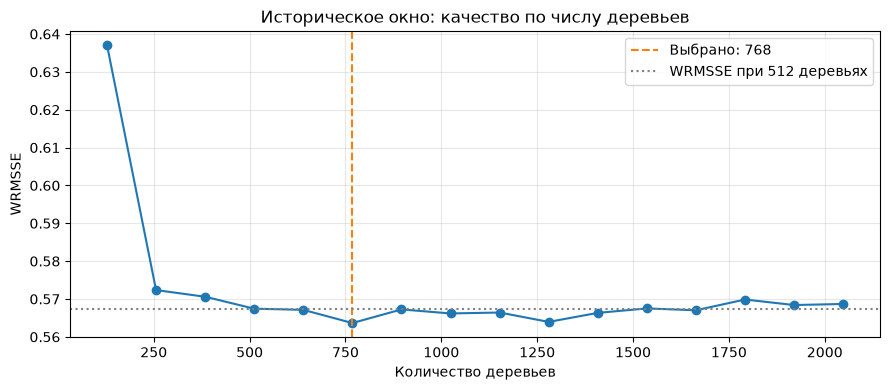

In [34]:
tree_dates = price_inner_evaluator.forecast_dates
tree_series_index = price_inner_evaluator.series_index

tree_validation_parts = []

for target_date in tree_dates:
    features = make_daily_features_with_cross_store(
        price_inner_origin,
        target_date,
    ).loc[:, tree_feature_columns]

    if not features.index.equals(tree_series_index):
        raise ValueError("Нарушен порядок товаров и магазинов.")

    tree_validation_parts.append(
        features.reset_index(drop=True)
    )

tree_X_valid = pd.concat(
    tree_validation_parts,
    ignore_index=True,
)

del tree_validation_parts

tree_validation_pool = Pool(
    tree_X_valid,
    cat_features=daily_categorical_features,
)

del tree_X_valid
gc.collect()

tree_checkpoints = list(
    range(TREE_STEP, TREE_MAX, TREE_STEP)
) + [TREE_MAX]

tree_stages = tree_scan_model.staged_predict(
    tree_validation_pool,
    prediction_type="Exponent",
    ntree_start=0,
    ntree_end=TREE_MAX,
    eval_period=TREE_STEP,
    thread_count=4,
)

tree_rows = []
tree_level_reports = {}

tree_best_score = np.inf
tree_best_trees = None
tree_best_valid_prediction = None

for trees, flat_prediction in zip(
    tree_checkpoints,
    tree_stages,
    strict=True,
):
    prediction_values = (
        np.asarray(flat_prediction, dtype=np.float64)
        .reshape(len(tree_dates), len(tree_series_index))
        .T
        * price_target_scale
    )

    prediction = pd.DataFrame(
        prediction_values,
        index=tree_series_index,
        columns=tree_dates,
    )

    metrics, report = price_evaluate(
        price_inner_evaluator,
        price_inner_actual,
        prediction,
    )

    tree_rows.append({
        "trees": trees,
        **metrics,
    })
    tree_level_reports[trees] = report

    if metrics["WRMSSE"] < tree_best_score:
        tree_best_score = metrics["WRMSSE"]
        tree_best_trees = int(trees)
        tree_best_valid_prediction = prediction.copy()

    print(
        f"{trees:4d} деревьев | "
        f"WRMSSE: {metrics['WRMSSE']:.5f} | "
        f"Bias: {metrics['Bias']:+.2%}"
    )

del tree_validation_pool, tree_stages
gc.collect()

tree_comparison = (
    pd.DataFrame(tree_rows)
    .set_index("trees")
)

tree_comparison["gain_vs_512"] = (
    1
    - tree_comparison["WRMSSE"]
    / tree_comparison.loc[512, "WRMSSE"]
)

display(
    tree_comparison.sort_values("WRMSSE").style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_512": "{:+.2%}",
    })
)

print(f"Лучшее из проверенных значений: {tree_best_trees} деревьев.")
print(f"Исторический WRMSSE: {tree_best_score:.5f}")

if tree_best_trees == TREE_MAX:
    print(
        "Минимум на верхней границе: "
        "следующим шагом стоит проверить больше деревьев."
    )
elif tree_best_trees == tree_checkpoints[0]:
    print(
        "Минимум на нижней границе: "
        "можно проверить меньше деревьев на этой же модели."
    )

tree_comparison.to_csv(
    tree_experiment_dir / "historical_tree_comparison.csv"
)

pd.DataFrame({
    trees: report["weighted_RMSSE"]
    for trees, report in tree_level_reports.items()
}).to_csv(
    tree_experiment_dir / "historical_levels_by_tree_count.csv"
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    tree_comparison.index,
    tree_comparison["WRMSSE"],
    marker="o",
)

ax.axvline(
    tree_best_trees,
    color="tab:orange",
    linestyle="--",
    label=f"Выбрано: {tree_best_trees}",
)

ax.axhline(
    tree_comparison.loc[512, "WRMSSE"],
    color="gray",
    linestyle=":",
    label="WRMSSE при 512 деревьях",
)

ax.set(
    title="Историческое окно: качество по числу деревьев",
    xlabel="Количество деревьев",
    ylabel="WRMSSE",
)

ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    tree_experiment_dir / "historical_wrmsse_curve.png",
    dpi=150,
)

plt.show()

### 10.2. Перенос выбранного числа на public

Обучаем модель на 768 деревьях по истории до public. Этот fit нужен для проверки переноса настройки на следующий период; историческую модель напрямую на public не применяем.


In [35]:
tree_final_params = {
    **cross_store_params,
    "iterations": tree_best_trees,
}

tree_final_seconds = 0.0

if tree_best_trees == int(cross_store_tree_count):
    print(
        f"Выбраны прежние {tree_best_trees} деревьев. "
        "Используем готовую public-модель."
    )

    tree_public_model = cb_cross_store_model
    tree_public_prediction = cross_store_public_prediction.copy()

else:
    print(
        f"Обучение для public-периода: "
        f"{tree_best_trees} деревьев."
    )

    tree_X, tree_y = build_feature_dataset(
        label_cutoff=cb_public_origin,
        feature_function=make_daily_features_with_cross_store,
        feature_columns=tree_feature_columns,
    )

    tree_public_model = CatBoostRegressor(**tree_final_params)

    tree_started = perf_counter()

    tree_public_model.fit(
        tree_X,
        tree_y / price_target_scale,
        cat_features=daily_categorical_features,
        use_best_model=False,
    )

    tree_final_seconds = perf_counter() - tree_started

    del tree_X, tree_y
    gc.collect()

    tree_public_prediction = price_predict(
        model=tree_public_model,
        origin=cb_public_origin,
        dates=wrmsse_evaluator.forecast_dates,
        feature_function=make_daily_features_with_cross_store,
        columns=tree_feature_columns,
    )

tree_public_metrics, tree_public_report = price_evaluate(
    wrmsse_evaluator,
    actual_daily,
    tree_public_prediction,
)

tree_model_name = (
    f"CatBoost — выбор по WRMSSE, {tree_best_trees} деревьев"
)

tree_public_comparison = cross_store_public_comparison[
    ["WRMSSE", "Bias"]
].copy()

tree_public_comparison.loc[tree_model_name] = [
    tree_public_metrics["WRMSSE"],
    tree_public_metrics["Bias"],
]

tree_public_comparison["gain_vs_512"] = (
    1
    - tree_public_comparison["WRMSSE"]
    / cross_store_public_metrics["WRMSSE"]
)

tree_public_comparison = (
    tree_public_comparison.sort_values("WRMSSE")
)

print("Public-период")

display(
    tree_public_comparison.style.format({
        "WRMSSE": "{:.5f}",
        "Bias": "{:+.2%}",
        "gain_vs_512": "{:+.2%}",
    })
)

tree_public_levels = cross_store_public_levels.copy()
tree_public_levels[tree_model_name] = (
    tree_public_report["weighted_RMSSE"]
)

print("Качество по уровням")
display(tree_public_levels.style.format("{:.5f}"))

tree_public_comparison.to_csv(
    tree_experiment_dir / "public_metrics.csv"
)
tree_public_levels.to_csv(
    tree_experiment_dir / "public_metrics_by_level.csv"
)
tree_public_prediction.to_csv(
    tree_experiment_dir / "public_predictions.csv.gz",
    compression="gzip",
)
tree_best_valid_prediction.to_csv(
    tree_experiment_dir / "historical_best_predictions.csv.gz",
    compression="gzip",
)

tree_config = {
    "params": tree_final_params,
    "features": tree_feature_columns,
    "categorical_features": daily_categorical_features,
    "target_scale": price_target_scale,
    "prediction_type": "Exponent",
    "selection_metric": "historical_WRMSSE",
    "checked_trees": tree_checkpoints,
    "selected_trees": tree_best_trees,
    "training_origins": CB_N_ORIGINS,
    "horizons_per_origin": 2,
    "historical_origin": str(price_inner_origin.date()),
    "public_origin": str(cb_public_origin.date()),
    "historical_metrics": {
        "WRMSSE": float(
            tree_comparison.loc[tree_best_trees, "WRMSSE"]
        ),
        "Bias": float(
            tree_comparison.loc[tree_best_trees, "Bias"]
        ),
    },
    "public_metrics": tree_public_metrics,
    "scan_fit_seconds": tree_scan_seconds,
    "final_fit_seconds": tree_final_seconds,
}

_ = (tree_experiment_dir / "config.json").write_text(
    json.dumps(tree_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

tree_public_model.save_model(
    str(tree_model_dir / "03_daily_catboost_trees_v6.cbm")
)

print(f"Результаты сохранены: {tree_experiment_dir}")

Обучение для public-периода: 768 деревьев.
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
0:	learn: 4.5356993	total: 791ms	remaining: 10m 6s
200:	learn: 3.6489150	total: 2m 12s	remaining: 6m 14s
400:	learn: 3.6292427	total: 4m 27s	remaining: 4m 4s
600:	learn: 3.6174717	total: 6m 38s	remaining: 1m 50s
767:	learn: 3.6113749	total: 8m 29s	remaining: 0us
Public-период


,WRMSSE,Bias,gain_vs_512
Метод,,,
CatBoost — отдел + другие магазины,0.64295,-5.27%,+0.00%
CatBoost — цена + регулярность + отдел,0.64888,-5.25%,-0.92%
"CatBoost — выбор по WRMSSE, 768 деревьев",0.65237,-5.81%,-1.47%
CatBoost — цена + регулярность,0.67781,-5.15%,-5.42%
CatBoost — с ценой,0.69174,-5.97%,-7.59%
CatBoost — без цены,0.71965,-6.74%,-11.93%
Среднее по дням недели за 4 недели,0.75242,-3.91%,-17.03%
Повтор последних 28 дней,0.83773,-3.91%,-30.29%
Повтор последней недели,0.86970,-7.36%,-35.27%


Качество по уровням


,Сезонный baseline,CatBoost — без цены,CatBoost — с ценой,CatBoost — цена + регулярность,CatBoost — цена + регулярность + отдел,CatBoost — отдел + другие магазины,"CatBoost — выбор по WRMSSE, 768 деревьев"
level,,,,,,,
Total,0.60561,0.60687,0.55355,0.51117,0.49300,0.47838,0.50936
State,0.64686,0.61926,0.57555,0.54354,0.51620,0.50682,0.53067
Store,0.69878,0.68382,0.65347,0.64026,0.58274,0.58480,0.59848
Category,0.64273,0.62135,0.57559,0.55013,0.52921,0.51146,0.52840
Department,0.72484,0.68306,0.64908,0.63708,0.59776,0.58309,0.58935
State / Category,0.68639,0.65567,0.61974,0.60198,0.56875,0.55995,0.57317
State / Department,0.75401,0.70744,0.68238,0.67595,0.63070,0.62611,0.62931
Store / Category,0.73778,0.71492,0.69100,0.68820,0.64033,0.64301,0.65089
Store / Department,0.79911,0.76733,0.75047,0.75421,0.70189,0.70756,0.70843


Результаты сохранены: /Users/daniilsestov/Desktop/pet_projects/demand-planner/results/m5_wrmsse/catboost_tree_scan_v6


768 деревьев улучшили историческое окно с **0.56744 до 0.56365**, но ухудшили public с **0.64295 до 0.65237**. Следующий опыт проверяет, сохраняется ли преимущество на других исторических месяцах.


## 11. Проверка на трёх исторических окнах

Одного месяца оказалось мало для выбора числа деревьев. Сравниваем 256, 512, 768 и 1024 дерева на трёх непересекающихся 28-дневных периодах.

| Дата прогноза | Проверочный период | Источник |
|---|---|---|
| 31 января 2016 | 1–28 февраля | Новое обучение |
| 28 февраля 2016 | 29 февраля — 27 марта | Новое обучение |
| 27 марта 2016 | 28 марта — 24 апреля | Сохранённый перебор |

Два новых fit выполняются до 1024 деревьев. Для каждого окна масштабы, денежные веса и обучающие целевые даты ограничены его прошлой историей. Признаки и остальные параметры те же.


In [36]:
import gc
import json
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, Pool


TRANSFER_TREES = [256, 512, 768, 1024]
TRANSFER_MAX_TREES = max(TRANSFER_TREES)

transfer_features = list(cross_store_feature_columns)

transfer_base_params = {
    key: value
    for key, value in cross_store_params.items()
    if key not in {"iterations", "verbose"}
}

transfer_params = {
    **transfer_base_params,
    "iterations": TRANSFER_MAX_TREES,
    "verbose": 256,
}

transfer_dir = RESULTS / "catboost_tree_transfer_v7"
transfer_dir.mkdir(parents=True, exist_ok=True)

transfer_models_dir = PROJECT_ROOT / "models"
transfer_models_dir.mkdir(parents=True, exist_ok=True)

transfer_previous_dir = RESULTS / "catboost_tree_scan_v6"

transfer_previous_config = json.loads(
    (transfer_previous_dir / "config.json").read_text(
        encoding="utf-8"
    )
)

transfer_previous_params = {
    key: value
    for key, value in transfer_previous_config["params"].items()
    if key not in {"iterations", "verbose"}
}

if (
    transfer_base_params != transfer_previous_params
    or transfer_features != transfer_previous_config["features"]
    or list(daily_categorical_features)
    != transfer_previous_config["categorical_features"]
    or float(price_target_scale)
    != float(transfer_previous_config["target_scale"])
    or int(CB_N_ORIGINS)
    != int(transfer_previous_config["training_origins"])
):
    raise ValueError(
        "Настройки отличаются от предыдущего перебора. "
        "Объединять эти результаты пока нельзя."
    )

transfer_last_origin = pd.Timestamp(
    transfer_previous_config["historical_origin"]
)

transfer_origins = [
    transfer_last_origin - pd.Timedelta(days=2 * HORIZON),
    transfer_last_origin - pd.Timedelta(days=HORIZON),
    transfer_last_origin,
]

transfer_config = {
    "params": transfer_params,
    "features": transfer_features,
    "categorical_features": list(daily_categorical_features),
    "target_scale": float(price_target_scale),
    "horizon": int(HORIZON),
    "training_origins": int(CB_N_ORIGINS),
    "horizons_per_origin": 2,
    "checked_trees": TRANSFER_TREES,
    "origins": [
        str(origin.date())
        for origin in transfer_origins
    ],
    "selection_metric": "mean_historical_WRMSSE",
}

transfer_config_path = transfer_dir / "config.json"

if transfer_config_path.exists():
    saved_config = json.loads(
        transfer_config_path.read_text(encoding="utf-8")
    )

    if saved_config != transfer_config:
        raise ValueError(
            "В этой папке сохранён опыт с другими настройками. "
            "Для нового опыта укажи другую папку результатов."
        )
else:
    transfer_config_path.write_text(
        json.dumps(
            transfer_config,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

transfer_previous_scores = (
    pd.read_csv(
        transfer_previous_dir
        / "historical_tree_comparison.csv"
    )
    .set_index("trees")
    .loc[TRANSFER_TREES]
)

transfer_reused_rows = []

for trees, row in transfer_previous_scores.iterrows():
    transfer_reused_rows.append({
        "fold": 3,
        "origin": transfer_last_origin,
        "score_start": (
            transfer_last_origin + pd.Timedelta(days=1)
        ),
        "score_end": (
            transfer_last_origin + pd.Timedelta(days=HORIZON)
        ),
        "trees": int(trees),
        "WRMSSE": float(row["WRMSSE"]),
        "Bias": float(row["Bias"]),
    })

transfer_windows = pd.DataFrame([
    {
        "fold": number,
        "origin": origin.date(),
        "score_start": (
            origin + pd.Timedelta(days=1)
        ).date(),
        "score_end": (
            origin + pd.Timedelta(days=HORIZON)
        ).date(),
        "status": (
            "Готовые результаты"
            if number == 3
            else "Новое обучение"
        ),
    }
    for number, origin in enumerate(
        transfer_origins,
        start=1,
    )
]).set_index("fold")

display(transfer_windows)

print(f"Признаков: {len(transfer_features)}")
print(f"Деревья для сравнения: {TRANSFER_TREES}")
print("Новых обучений: 2")

,origin,score_start,score_end,status
fold,,,,
1,2016-01-31,2016-02-01,2016-02-28,Новое обучение
2,2016-02-28,2016-02-29,2016-03-27,Новое обучение
3,2016-03-27,2016-03-28,2016-04-24,Готовые результаты


Признаков: 63
Деревья для сравнения: [256, 512, 768, 1024]
Новых обучений: 2


### 11.1. Два новых обучения

После каждого окна сохраняем модель и метрики. Повторный запуск пропускает готовые результаты; если сохранена только модель, заново считает прогнозы без fit.


In [37]:
def transfer_check_window(origin, fold_number):
    origin = pd.Timestamp(origin)

    window_dir = (
        transfer_dir / f"origin_{origin:%Y-%m-%d}"
    )
    window_dir.mkdir(parents=True, exist_ok=True)

    metrics_path = window_dir / "metrics.csv"

    model_path = transfer_models_dir / (
        f"03_daily_catboost_transfer_"
        f"{origin:%Y-%m-%d}_v7.cbm"
    )

    print(
        f"\nОкно {fold_number}/3: "
        f"{origin + pd.Timedelta(days=1):%Y-%m-%d}"
        " — "
        f"{origin + pd.Timedelta(days=HORIZON):%Y-%m-%d}",
        flush=True,
    )

    if metrics_path.exists():
        cached_metrics = pd.read_csv(
            metrics_path,
            parse_dates=[
                "origin",
                "score_start",
                "score_end",
            ],
        )

        if (
            sorted(cached_metrics["trees"].tolist())
            == TRANSFER_TREES
            and np.isfinite(
                cached_metrics[["WRMSSE", "Bias"]]
                .to_numpy()
            ).all()
        ):
            print("Результаты уже готовы: пропускаем окно.")
            return cached_metrics

    window_started = perf_counter()

    history = daily_history.loc[:, :origin]

    weight_weeks = daily_calendar.loc[
        history.columns[-28:],
        "wm_yr_wk",
    ].unique()

    evaluator = M5WRMSSE(
        history=history,
        metadata=series_metadata,
        calendar=calendar,
        prices=price_data.loc[
            price_data["wm_yr_wk"].isin(weight_weeks)
        ],
        levels=M5_LEVELS,
        horizon=HORIZON,
    )

    actual = daily_history.loc[
        :,
        evaluator.forecast_dates,
    ]

    model = CatBoostRegressor(**transfer_params)

    if model_path.exists():
        model.load_model(str(model_path))

        if (
            model.tree_count_ != TRANSFER_MAX_TREES
            or model.feature_names_ != transfer_features
        ):
            raise ValueError(
                "Сохранённая модель не соответствует настройкам."
            )

        print("Сохранённая модель загружена.")

    else:
        X_train, y_train = build_feature_dataset(
            label_cutoff=origin,
            feature_function=(
                make_daily_features_with_cross_store
            ),
            feature_columns=transfer_features,
        )

        print(
            f"Обучающих строк: {len(X_train):,}. "
            f"Обучаем {TRANSFER_MAX_TREES} деревьев.",
            flush=True,
        )

        fit_started = perf_counter()

        model.fit(
            X_train,
            y_train / price_target_scale,
            cat_features=daily_categorical_features,
            use_best_model=False,
        )

        fit_seconds = perf_counter() - fit_started

        model.save_model(str(model_path))

        del X_train, y_train
        gc.collect()

        print(
            f"Обучение: {fit_seconds / 60:.1f} мин.",
            flush=True,
        )

    validation_parts = []

    for target_date in evaluator.forecast_dates:
        features = make_daily_features_with_cross_store(
            origin,
            target_date,
        ).loc[:, transfer_features]

        if not features.index.equals(
            evaluator.series_index
        ):
            raise ValueError(
                "Нарушен порядок товаров и магазинов."
            )

        validation_parts.append(
            features.reset_index(drop=True)
        )

    X_valid = pd.concat(
        validation_parts,
        ignore_index=True,
    )

    del validation_parts

    validation_pool = Pool(
        X_valid,
        cat_features=daily_categorical_features,
    )

    del X_valid
    gc.collect()

    stages = model.staged_predict(
        validation_pool,
        prediction_type="Exponent",
        ntree_start=0,
        ntree_end=TRANSFER_MAX_TREES,
        eval_period=256,
        thread_count=4,
    )

    rows = []
    level_tables = []

    for trees, flat_prediction in zip(
        TRANSFER_TREES,
        stages,
        strict=True,
    ):
        values = (
            np.asarray(
                flat_prediction,
                dtype=np.float64,
            )
            .reshape(
                len(evaluator.forecast_dates),
                len(evaluator.series_index),
            )
            .T
            * price_target_scale
        )

        prediction = pd.DataFrame(
            values,
            index=evaluator.series_index,
            columns=evaluator.forecast_dates,
        )

        metrics, report = price_evaluate(
            evaluator,
            actual,
            prediction,
        )

        rows.append({
            "fold": fold_number,
            "origin": origin,
            "score_start": evaluator.forecast_dates[0],
            "score_end": evaluator.forecast_dates[-1],
            "trees": trees,
            **metrics,
        })

        level_tables.append(
            report.assign(trees=trees).reset_index()
        )

        print(
            f"{trees:4d} деревьев | "
            f"WRMSSE: {metrics['WRMSSE']:.5f} | "
            f"Bias: {metrics['Bias']:+.2%}",
            flush=True,
        )

    fold_metrics = pd.DataFrame(rows)

    pd.concat(
        level_tables,
        ignore_index=True,
    ).to_csv(
        window_dir / "metrics_by_level.csv",
        index=False,
    )

    fold_metrics.to_csv(
        metrics_path,
        index=False,
    )

    del validation_pool, stages, model
    gc.collect()

    print(
        "Окно целиком: "
        f"{(perf_counter() - window_started) / 60:.1f} мин.",
        flush=True,
    )

    return fold_metrics


transfer_tables = [
    pd.DataFrame(transfer_reused_rows)
]

for fold_number, origin in enumerate(
    transfer_origins[:-1],
    start=1,
):
    fold_metrics = transfer_check_window(
        origin=origin,
        fold_number=fold_number,
    )

    transfer_tables.append(fold_metrics)

    transfer_results = (
        pd.concat(
            transfer_tables,
            ignore_index=True,
        )
        .sort_values(["fold", "trees"])
        .reset_index(drop=True)
    )

    transfer_results.to_csv(
        transfer_dir / "all_windows_metrics.csv",
        index=False,
    )

print("\nДва новых окна готовы.")


Окно 1/3: 2016-02-01 — 2016-02-28
Масштабы: Total — 1 рядов
Масштабы: State — 3 рядов
Масштабы: Store — 10 рядов
Масштабы: Category — 3 рядов
Масштабы: Department — 7 рядов
Масштабы: State / Category — 9 рядов
Масштабы: State / Department — 21 рядов
Масштабы: Store / Category — 30 рядов
Масштабы: Store / Department — 70 рядов
Масштабы: Item — 3,049 рядов
Масштабы: Item / State — 9,147 рядов
Масштабы: Item / Store — 30,490 рядов
Подготовлено дат: 13/52
Подготовлено дат: 26/52
Подготовлено дат: 39/52
Подготовлено дат: 52/52
Обучающих строк: 3,170,960. Обучаем 1024 деревьев.
0:	learn: 4.4617633	total: 843ms	remaining: 14m 22s
256:	learn: 3.5786434	total: 2m 49s	remaining: 8m 26s
512:	learn: 3.5599500	total: 5m 45s	remaining: 5m 43s
768:	learn: 3.5472587	total: 8m 37s	remaining: 2m 51s
1023:	learn: 3.5393655	total: 11m 28s	remaining: 0us
Обучение: 11.5 мин.
 256 деревьев | WRMSSE: 0.72553 | Bias: -4.06%
 512 деревьев | WRMSSE: 0.75826 | Bias: -5.17%
 768 деревьев | WRMSSE: 0.76738 | Bias:

### 11.2. Среднее качество и устойчивость

Основной критерий выбора — средний WRMSSE трёх окон с одинаковым весом каждого окна. Дополнительно смотрим относительное улучшение к 512, худший результат и число выигранных окон.

`mean_gain_vs_512` — среднее трёх относительных улучшений. Оно может отличаться от относительного изменения среднего WRMSSE. На графике значение выше нуля означает улучшение к 512.


WRMSSE по окнам: меньше — лучше


trees,256,512,768,1024
window,,,,
2016-02-01 — 2016-02-28,0.72553,0.75826,0.76738,0.77116
2016-02-29 — 2016-03-27,0.67147,0.65485,0.65742,0.65895
2016-03-28 — 2016-04-24,0.57236,0.56744,0.56365,0.56618


Изменение относительно 512: плюс — улучшение


trees,256,512,768,1024
window,,,,
2016-02-01 — 2016-02-28,+4.32%,+0.00%,-1.20%,-1.70%
2016-02-29 — 2016-03-27,-2.54%,+0.00%,-0.39%,-0.63%
2016-03-28 — 2016-04-24,-0.87%,+0.00%,+0.67%,+0.22%


Общее сравнение


,mean_WRMSSE,mean_gain_vs_512,worst_gain_vs_512,wins_vs_512,mean_Bias
trees,,,,,
256,0.65645,+0.30%,-2.54%,1,-2.14%
512,0.66018,+0.00%,+0.00%,0,-2.79%
768,0.66282,-0.31%,-1.20%,1,-2.95%
1024,0.66543,-0.70%,-1.70%,1,-3.12%


Минимальный средний WRMSSE: 256 деревьев.


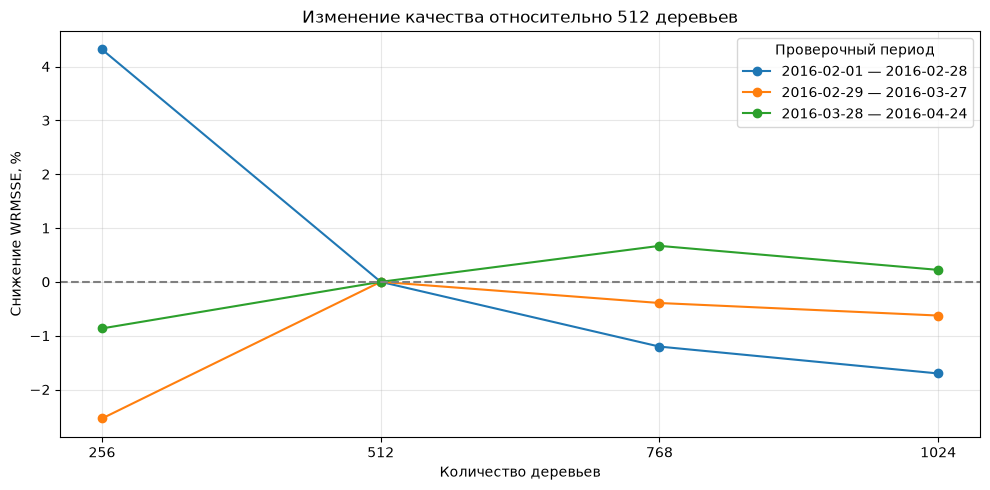

In [38]:
transfer_results["window"] = (
    pd.to_datetime(transfer_results["score_start"])
    .dt.strftime("%Y-%m-%d")
    + " — "
    + pd.to_datetime(transfer_results["score_end"])
    .dt.strftime("%Y-%m-%d")
)

transfer_matrix = (
    transfer_results.pivot(
        index="window",
        columns="trees",
        values="WRMSSE",
    )
    .sort_index()
    .loc[:, TRANSFER_TREES]
)

transfer_gains = (
    1
    - transfer_matrix.div(
        transfer_matrix[512],
        axis=0,
    )
)

transfer_summary = pd.DataFrame({
    "mean_WRMSSE": transfer_matrix.mean(),
    "mean_gain_vs_512": transfer_gains.mean(),
    "worst_gain_vs_512": transfer_gains.min(),
    "wins_vs_512": (
        transfer_gains > 1e-10
    ).sum(),
    "mean_Bias": (
        transfer_results
        .groupby("trees")["Bias"]
        .mean()
    ),
}).sort_values("mean_WRMSSE")

transfer_summary.index.name = "trees"

print("WRMSSE по окнам: меньше — лучше")
display(
    transfer_matrix.style.format("{:.5f}")
)

print("Изменение относительно 512: плюс — улучшение")
display(
    transfer_gains.style.format("{:+.2%}")
)

print("Общее сравнение")
display(
    transfer_summary.style.format({
        "mean_WRMSSE": "{:.5f}",
        "mean_gain_vs_512": "{:+.2%}",
        "worst_gain_vs_512": "{:+.2%}",
        "wins_vs_512": "{:.0f}",
        "mean_Bias": "{:+.2%}",
    })
)

transfer_selected_trees = int(
    transfer_summary["mean_WRMSSE"].idxmin()
)

print(
    "Минимальный средний WRMSSE: "
    f"{transfer_selected_trees} деревьев."
)

transfer_matrix.to_csv(
    transfer_dir / "wrmsse_by_window.csv"
)

transfer_summary.to_csv(
    transfer_dir / "summary.csv"
)

fig, ax = plt.subplots(figsize=(10, 5))

for window, gains in transfer_gains.iterrows():
    ax.plot(
        TRANSFER_TREES,
        gains.to_numpy() * 100,
        marker="o",
        label=window,
    )

ax.axhline(
    0,
    color="gray",
    linestyle="--",
)

ax.set(
    title="Изменение качества относительно 512 деревьев",
    xlabel="Количество деревьев",
    ylabel="Снижение WRMSSE, %",
)

ax.set_xticks(TRANSFER_TREES)
ax.grid(alpha=0.3)
ax.legend(title="Проверочный период")
fig.tight_layout()

fig.savefig(
    transfer_dir / "transferability.png",
    dpi=150,
)

plt.show()

| Деревьев | Средний WRMSSE | Лучших окон из трёх |
|---:|---:|---:|
| **256** | **0.65645** | 1 |
| 512 | 0.66018 | 1 |
| 768 | 0.66282 | 1 |
| 1024 | 0.66543 | 0 |

256 деревьев дают минимальное среднее, на 0.57% ниже 512. Выигрыш обеспечивает февраль: на двух следующих окнах 256 проигрывают 512. Преимущество небольшое и зависит от периода; настройку дополнительно проверяем на public.


## 12. Текущий контроль: 256 деревьев

По среднему историческому WRMSSE выбираем 256 деревьев и проверяем их на public. Берём первые 256 деревьев уже сохранённой public-модели на 512 через `ntree_end=256`. Новое обучение не требуется.

Модель на диске остаётся на 512 деревьях. Поэтому в настройках отдельно храним параметры исходной модели и число деревьев, использованное для текущего прогноза.


In [39]:
import json
from time import perf_counter

import numpy as np
import pandas as pd
from catboost import CatBoostRegressor


public256_source_dir = (
    RESULTS / "public_catboost_cross_store_v5"
)

public256_source_config = json.loads(
    (public256_source_dir / "config.json").read_text(
        encoding="utf-8"
    )
)

public256_features = list(
    public256_source_config["features"]
)

public256_origin = pd.Timestamp(
    public256_source_config["public_origin"]
)

public256_scale = float(
    public256_source_config["target_scale"]
)

if public256_features != list(cross_store_feature_columns):
    raise ValueError(
        "Текущие признаки отличаются от сохранённой модели."
    )

if public256_origin != pd.Timestamp(cb_public_origin):
    raise ValueError(
        "Дата public-прогноза отличается от предыдущего опыта."
    )

public256_model = CatBoostRegressor()

public256_model.load_model(
    str(
        PROJECT_ROOT
        / "models"
        / "03_daily_catboost_cross_store_v5.cbm"
    )
)

if (
    public256_model.tree_count_ != 512
    or public256_model.feature_names_ != public256_features
):
    raise ValueError(
        "Загружена модель с другим числом деревьев "
        "или набором признаков."
    )

public256_dates = wrmsse_evaluator.forecast_dates

if public256_dates[0] != (
    public256_origin + pd.Timedelta(days=1)
):
    raise ValueError("Проверочный период не совпадает.")

public256_values = np.empty(
    (
        len(wrmsse_evaluator.series_index),
        len(public256_dates),
    ),
    dtype=np.float64,
)

public256_started = perf_counter()

for number, target_date in enumerate(public256_dates):
    features = make_daily_features_with_cross_store(
        public256_origin,
        target_date,
    ).loc[:, public256_features]

    if not features.index.equals(
        wrmsse_evaluator.series_index
    ):
        raise ValueError(
            "Нарушен порядок товаров и магазинов."
        )

    public256_values[:, number] = (
        public256_model.predict(
            features,
            prediction_type="Exponent",
            ntree_start=0,
            ntree_end=256,
            thread_count=4,
        )
        * public256_scale
    )

    if (number + 1) % 7 == 0:
        print(
            f"Спрогнозировано дней: "
            f"{number + 1}/{len(public256_dates)}",
            flush=True,
        )

public256_prediction = pd.DataFrame(
    public256_values,
    index=wrmsse_evaluator.series_index,
    columns=public256_dates,
)

public256_metrics, public256_report = price_evaluate(
    wrmsse_evaluator,
    actual_daily,
    public256_prediction,
)

print(
    f"\nWRMSSE: {public256_metrics['WRMSSE']:.5f}\n"
    f"Bias: {public256_metrics['Bias']:+.2%}\n"
    f"Расчёт занял: "
    f"{perf_counter() - public256_started:.0f} сек."
)

Спрогнозировано дней: 7/28
Спрогнозировано дней: 14/28
Спрогнозировано дней: 21/28
Спрогнозировано дней: 28/28

WRMSSE: 0.64089
Bias: -4.39%
Расчёт занял: 1 сек.


### 12.1. Сводная таблица и сохранение контроля

Рядом показываем среднюю историческую оценку и public-результат для 256, 512 и 768 деревьев. Они относятся к разным периодам; сравниваем варианты внутри каждого столбца.

Служебные поля версии на 256 деревьев приведены в соответствие с `inference_ntree_end`: историческая метрика относится к первым 256 деревьям. Сам прогноз и уже рассчитанные метрики при оформлении не пересчитывались.


In [ ]:
public256_scan_config = json.loads(
    (
        RESULTS
        / "catboost_tree_scan_v6"
        / "config.json"
    ).read_text(encoding="utf-8")
)

public256_common_params = {
    key: value
    for key, value in public256_source_config["params"].items()
    if key not in {"iterations", "verbose"}
}

public256_scan_params = {
    key: value
    for key, value in public256_scan_config["params"].items()
    if key not in {"iterations", "verbose"}
}

if (
    int(public256_scan_config["selected_trees"]) != 768
    or public256_scan_config["features"] != public256_features
    or public256_scan_config["public_origin"]
    != public256_source_config["public_origin"]
    or public256_scan_params != public256_common_params
    or float(public256_scan_config["target_scale"])
    != public256_scale
):
    raise ValueError(
        "Сохранённый результат 768 деревьев "
        "получен с другими настройками."
    )

public256_comparison = pd.DataFrame.from_dict(
    {
        256: public256_metrics,
        512: public256_source_config["public_metrics"],
        768: public256_scan_config["public_metrics"],
    },
    orient="index",
)

public256_comparison.index.name = "trees"

public256_comparison = public256_comparison.rename(
    columns={
        "WRMSSE": "public_WRMSSE",
        "Bias": "public_Bias",
    }
)

public256_history_summary = pd.read_csv(
    RESULTS
    / "catboost_tree_transfer_v7"
    / "summary.csv",
    index_col="trees",
)

public256_comparison["historical_mean_WRMSSE"] = (
    public256_history_summary["mean_WRMSSE"]
    .reindex(public256_comparison.index)
)

public256_comparison["public_gain_vs_512"] = (
    1
    - public256_comparison["public_WRMSSE"]
    / public256_comparison.loc[512, "public_WRMSSE"]
)

public256_comparison = public256_comparison[
    [
        "historical_mean_WRMSSE",
        "public_WRMSSE",
        "public_Bias",
        "public_gain_vs_512",
    ]
]

display(
    public256_comparison.style.format({
        "historical_mean_WRMSSE": "{:.5f}",
        "public_WRMSSE": "{:.5f}",
        "public_Bias": "{:+.2%}",
        "public_gain_vs_512": "{:+.2%}",
    })
)

public256_dir = RESULTS / "public_catboost_256_v8"
public256_dir.mkdir(parents=True, exist_ok=True)

public256_comparison.to_csv(
    public256_dir / "comparison.csv"
)

public256_report.to_csv(
    public256_dir / "metrics_by_level.csv"
)

public256_prediction.to_csv(
    public256_dir / "predictions.csv.gz",
    compression="gzip",
)

public256_historical_scan = pd.read_csv(
    RESULTS
    / "catboost_tree_scan_v6"
    / "historical_tree_comparison.csv",
    index_col="trees",
)

public256_config = {
    **public256_source_config,
    "params": {
        **public256_source_config["params"],
        "iterations": 256,
    },
    "source_model": "03_daily_catboost_cross_store_v5.cbm",
    "source_model_trees": 512,
    "source_model_params": public256_source_config["params"],
    "source_model_historical_metrics": (
        public256_source_config["historical_metrics"]
    ),
    "inference_ntree_end": 256,
    "selection_metric": "mean_historical_WRMSSE",
    "status": "current_control",
    "historical_metrics": {
        "WRMSSE": float(
            public256_historical_scan.loc[256, "WRMSSE"]
        ),
        "Bias": float(
            public256_historical_scan.loc[256, "Bias"]
        ),
    },
    "historical_validation": {
        "windows": 3,
        "mean_WRMSSE": float(
            public256_history_summary.loc[256, "mean_WRMSSE"]
        ),
        "mean_Bias": float(
            public256_history_summary.loc[256, "mean_Bias"]
        ),
    },
    "public_metrics": public256_metrics,
}

(public256_dir / "config.json").write_text(
    json.dumps(
        public256_config,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(f"Результаты сохранены: {public256_dir}")

### Результат на конец работы 20 октября 2026

| Деревьев | Средний исторический WRMSSE | Public WRMSSE | Public Bias |
|---:|---:|---:|---:|
| **256** | **0.65645** | **0.64089** | **−4.39%** |
| 512 | 0.66018 | 0.64295 | −5.27% |
| 768 | 0.66282 | 0.65237 | −5.81% |

Принимаем **256 деревьев как текущий контроль** с 63 признаками. Public WRMSSE ниже сезонного бейзлайна на **14.82%**, ниже версии на 512 деревьях — на **0.32%**. Это лучшие результаты среди проверенных здесь вариантов; обобщение на другие периоды ещё требует проверки.

Контрольные файлы: `results/m5_wrmsse/public_catboost_256_v8/`. Исторические окна: `results/m5_wrmsse/catboost_tree_transfer_v7/`. Полные прогнозы и модели сохраняются локально; в Git входят ноутбук, метрики, параметры и графики.


## 13. С чего продолжить

- Начать с **Optuna**: глубина, скорость обучения и L2-регуляризация; число деревьев выбирать вместе с ними.
- Цель подбора — средний WRMSSE трёх исторических окон. Public использовать для проверки выбранного варианта.
- Контроль: 63 признака, Tweedie 1.5, depth 6, learning_rate 0.05, l2_leaf_reg 5, **256 деревьев**.
- Если ядро перезапущено, сначала подготовить восстановление данных, функций признаков и сохранённых моделей. Старые fit повторять для этого не требуется.
- Перед финальной оценкой сверить WRMSSE с эталоном организаторов. Зарезервированный период 23 мая — 19 июня 2016 пока не использовать для подбора.
